# Clase 9 — Agentes: aprender y evaluar sin simulador

**RL a ciegas** · mini curso de aprendizaje por refuerzo · vía profunda

> Un agente es cualquier cosa que observa, actúa y recibe una recompensa. La diferencia entre la cueva y el mundo real es que en el mundo real **no hay simulador**: hay que aprender y evaluar con lo que ya pasó.

1. **El bucle ReAct** (pensamiento → acción → observación): la forma general del ciclo agente–entorno. Un modelo de lenguaje real (Qwen2.5-0.5B) juega la cueva con herramientas, y lo comparamos con el azar y con Q-learning.
2. **El feed como MDP con γ ≈ 0**: ordenar publicaciones por el clic de hoy vs. por el usuario que vuelve mañana.
3. **RL sin simulador**: ReAgent y la **evaluación contrafactual** de políticas, en la cueva. Cierre con RL *offline*.
4. **De ReAgent a Pearl y a los LLM**.

> Ejecutar las celdas en orden. Tarda unos 5 minutos en CPU (casi todo es el agente ReAct, que usa un modelo de lenguaje real; la primera vez descarga ≈ 1 GB). En Colab con GPU, menos de 2.

## Preparación

La primera celda escribe `cave_env.py` (la cueva del curso) para que el notebook funcione solo, también en Colab.

In [1]:
%%writefile cave_env.py
"""
cave_env.py — La cueva a ciegas (entorno del mini curso de RL).

Una grilla discreta. El agente no ve el mapa: solo se entera de que hay una
pared cuando choca contra ella (en el juego, la pared se pinta de gris claro).
La salida es el cuadrado verde 'G'.

API mínima (estilo Gymnasium, sin dependencias):
    env = CaveEnv()
    s = env.reset()                 # estado = índice entero de la casilla
    s, r, done, info = env.step(a)  # a en {0:arriba, 1:derecha, 2:abajo, 3:izquierda}
    info["bump"]                    # True si chocó con una pared

Para la clase 3 (con modelo): env.P[s, a, s'] y env.R[s, a].
"""
import numpy as np

CAVE_MAP = [
    "##############",
    "#S...#.......#",
    "#.##.#.####..#",
    "#.#..#....#..#",
    "#.#.####..#.##",
    "#.#......##..#",
    "#.####.#..#..#",
    "#......#.##..#",
    "###.####....G#",
    "##############",
]

ACTIONS = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}
ACTION_NAMES = ["↑", "→", "↓", "←"]


class CaveEnv:
    def __init__(self, cave_map=CAVE_MAP, goal_reward=1.0, step_reward=0.0,
                 bump_reward=0.0, slip=0.0, max_steps=200, seed=None):
        self.grid = np.array([list(row) for row in cave_map])
        self.H, self.W = self.grid.shape
        self.goal_reward, self.step_reward, self.bump_reward = goal_reward, step_reward, bump_reward
        self.slip, self.max_steps = slip, max_steps
        self.rng = np.random.default_rng(seed)
        self.free = [(r, c) for r in range(self.H) for c in range(self.W) if self.grid[r, c] != "#"]
        self.pos2s = {p: i for i, p in enumerate(self.free)}
        self.nS, self.nA = len(self.free), 4
        self.start = self.pos2s[tuple(np.argwhere(self.grid == "S")[0])]
        self.goal = self.pos2s[tuple(np.argwhere(self.grid == "G")[0])]
        self._build_model()
        self.reset()

    # ---------- dinámica ----------
    def _move(self, s, a):
        r, c = self.free[s]
        dr, dc = ACTIONS[a]
        nr, nc = r + dr, c + dc
        if self.grid[nr, nc] == "#":
            return s, True
        return self.pos2s[(nr, nc)], False

    def _reward(self, s_next, bump):
        if s_next == self.goal:
            return self.goal_reward
        return self.step_reward + (self.bump_reward if bump else 0.0)

    def _build_model(self):
        """Modelo del mundo: P[s,a,s'] y R[s,a] (recompensa esperada). La meta es absorbente."""
        nS, nA = self.nS, self.nA
        self.P = np.zeros((nS, nA, nS))
        self.R = np.zeros((nS, nA))
        for s in range(nS):
            for a in range(nA):
                if s == self.goal:
                    self.P[s, a, s] = 1.0
                    continue
                # con prob 1-slip va adonde quiere; con slip, a una dirección perpendicular
                outcomes = [(a, 1 - self.slip)]
                if self.slip > 0:
                    outcomes += [((a + 1) % 4, self.slip / 2), ((a + 3) % 4, self.slip / 2)]
                for aa, p in outcomes:
                    s2, bump = self._move(s, aa)
                    self.P[s, a, s2] += p
                    self.R[s, a] += p * self._reward(s2, bump)

    def reset(self):
        self.s, self.t = self.start, 0
        self.touched = set()          # paredes descubiertas (para dibujar)
        return self.s

    def step(self, a):
        if self.slip > 0 and self.rng.random() < self.slip:
            a = (a + self.rng.choice([1, 3])) % 4
        s2, bump = self._move(self.s, a)
        if bump:
            r, c = self.free[self.s]
            dr, dc = ACTIONS[a]
            self.touched.add((r + dr, c + dc))
        rew = self._reward(s2, bump)
        self.s, self.t = s2, self.t + 1
        done = s2 == self.goal or self.t >= self.max_steps
        return s2, rew, done, {"bump": bump, "reached_goal": s2 == self.goal}

    # ---------- observaciones para Deep RL ----------
    def observe(self, s=None, kind="onehot"):
        s = self.s if s is None else s
        if kind == "onehot":
            x = np.zeros(self.nS, dtype=np.float32); x[s] = 1; return x
        r, c = self.free[s]
        if kind == "coords":
            return np.array([r / (self.H - 1), c / (self.W - 1)], dtype=np.float32)
        if kind == "coords+touch":   # posición + 4 "bigotes" que sienten paredes vecinas
            walls = [float(self.grid[r + dr, c + dc] == "#") for dr, dc in ACTIONS.values()]
            return np.array([r / (self.H - 1), c / (self.W - 1)] + walls, dtype=np.float32)
        raise ValueError(kind)

    # ---------- dibujo ----------
    def to_grid(self, values):
        g = np.full((self.H, self.W), np.nan)
        for s, (r, c) in enumerate(self.free):
            g[r, c] = values[s]
        return g

    def plot(self, values=None, policy=None, ax=None, title=None, cmap="magma",
             show_walls=True, path=None):
        import matplotlib.pyplot as plt
        if ax is None:
            _, ax = plt.subplots(figsize=(self.W * 0.5, self.H * 0.5))
        bg = np.zeros((self.H, self.W, 3))
        if show_walls:
            bg[self.grid == "#"] = 0.8      # gris claro: la pared "tocada"
        ax.imshow(bg)
        if values is not None:
            im = ax.imshow(self.to_grid(values), cmap=cmap, alpha=0.9)
            plt.colorbar(im, ax=ax, fraction=0.03)
        gr, gc = self.free[self.goal]
        ax.add_patch(plt.Rectangle((gc - .5, gr - .5), 1, 1, color="#2ecc71"))
        sr, sc = self.free[self.start]
        ax.text(sc, sr, "S", ha="center", va="center", color="w", fontsize=11, weight="bold")
        if policy is not None:
            for s, (r, c) in enumerate(self.free):
                if s != self.goal:
                    ax.text(c, r, ACTION_NAMES[int(policy[s])], ha="center", va="center",
                            color="cyan", fontsize=11)
        if path is not None:
            rc = np.array([self.free[s] for s in path])
            ax.plot(rc[:, 1], rc[:, 0], "-", color="#3498db", lw=2, alpha=.8)
        ax.set_xticks([]); ax.set_yticks([])
        if title: ax.set_title(title)
        return ax

Overwriting cave_env.py


Imports y semilla fija para que todos veamos los mismos resultados.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from cave_env import CaveEnv, ACTION_NAMES

SEMILLA = 0
np.random.seed(SEMILLA)

**Herramientas** (celda plegada): simuladores, estimadores y funciones de dibujo. No hace falta leerla, solo ejecutarla.

In [3]:
# @title Herramientas (no hace falta leer esto)
# Herramientas: no hace falta leer esto
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from matplotlib.colors import ListedColormap

COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#888888", "axes.titlesize": 12, "font.size": 10.5, "lines.linewidth": 2,
})


def value_iteration(P, R, gamma, tol=1e-10):
    """P[s,a,s'], R[s,a]. Devuelve V, política y Q (clase 3)."""
    V = np.zeros(P.shape[0])
    for _ in range(100000):
        Q = R + gamma * P @ V
        V_nuevo = Q.max(1)
        if np.max(np.abs(V_nuevo - V)) < tol:
            break
        V = V_nuevo
    return V_nuevo, Q.argmax(1), Q


# ================= 1. ciclos de agente =================
def _caja(ax, x, y, texto, color, w=2.3, h=0.9):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.08",
                                fc=color, ec="none", alpha=0.95))
    ax.text(x, y, texto, ha="center", va="center", color="white", fontsize=10.5, weight="bold")


def _flecha(ax, p, q, texto="", curva=0.25):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=16, color="#555",
                                 lw=1.6, connectionstyle=f"arc3,rad={curva}", shrinkA=30, shrinkB=30))
    if texto:
        mx, my = (p[0] + q[0]) / 2, (p[1] + q[1]) / 2
        ax.text(mx, my, texto, ha="center", va="center", fontsize=9.5, color="#333",
                bbox=dict(fc="white", ec="none", pad=1))


def dibujar_ciclos():
    fig, axs = plt.subplots(1, 2, figsize=(14, 5.6))
    # cueva
    ax = axs[0]
    _caja(ax, 0, 2.2, "agente\n(la política π)", COLORES[0])
    _caja(ax, 0, -2.2, "cueva\n(entorno)", COLORES[2])
    _flecha(ax, (0.2, 1.7), (0.2, -1.7), "acción\n↑ → ↓ ←", curva=-0.6)
    _flecha(ax, (-0.2, -1.7), (-0.2, 1.7), "observación: casilla\nrecompensa: +1 en la salida", curva=-0.6)
    ax.set_title("El agente de la cueva", fontsize=13)
    # LLM con el bucle ReAct
    ax = axs[1]
    pos = {"preg": (0, 2.6), "pens": (2.6, 1.0), "herr": (2.0, -2.0), "obs": (-2.0, -2.0), "resp": (-2.6, 1.0)}
    _caja(ax, *pos["preg"], "pregunta", COLORES[6])
    _caja(ax, *pos["pens"], "Pensamiento\n(texto del LLM)", COLORES[0])
    _caja(ax, *pos["herr"], "Acción\nbuscar / leer", COLORES[1])
    _caja(ax, *pos["obs"], "Observación\n(resultado)", COLORES[2])
    _caja(ax, *pos["resp"], "responder", COLORES[3])
    _flecha(ax, pos["preg"], pos["pens"], curva=-0.2)
    _flecha(ax, pos["pens"], pos["herr"], curva=-0.2)
    _flecha(ax, pos["herr"], pos["obs"], "la herramienta\ndevuelve", curva=-0.2)
    _flecha(ax, pos["obs"], pos["pens"], "vuelve al\ncontexto", curva=0.15)
    _flecha(ax, pos["pens"], pos["resp"], "acción final", curva=0.25)
    ax.text(-2.6, -0.2, "recompensa:\n¿la respuesta\nes correcta?", ha="center", va="top", fontsize=9.5,
            color=COLORES[3], weight="bold")
    ax.set_title("Un agente ReAct de LLM (deep search, clase 8)", fontsize=13)
    for ax in axs:
        ax.set_xlim(-4, 4); ax.set_ylim(-3.2, 3.4); ax.set_aspect("equal"); ax.axis("off")
    plt.tight_layout(); plt.show()


# ================= 2. feed =================
def dibujar_ranking(posts, probs, pesos, nombres_prob):
    """Toy del ranking publicado: probabilidades predichas -> puntaje ponderado -> orden."""
    probs = np.asarray(probs); w = np.asarray(pesos)
    puntaje = probs @ w
    orden = np.argsort(-puntaje)
    fig, axs = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
    ax = axs[0]
    im = ax.imshow(probs, cmap="Blues", vmin=0, vmax=probs.max() * 1.1, aspect="auto")
    for i in range(probs.shape[0]):
        for j in range(probs.shape[1]):
            ax.text(j, i, f"{probs[i, j]:.2f}", ha="center", va="center", fontsize=10,
                    color="white" if probs[i, j] > probs.max() * 0.6 else "#222")
    ax.set_xticks(range(len(nombres_prob)))
    ax.set_xticklabels([f"{n}\npeso {p:+g}" for n, p in zip(nombres_prob, w)])
    ax.set_yticks(range(len(posts))); ax.set_yticklabels(posts); ax.grid(False)
    ax.set_title("Paso A — redes multitarea: probabilidades predichas")
    ax = axs[1]
    bars = ax.barh([posts[i] for i in orden][::-1], puntaje[orden][::-1],
                   color=[COLORES[1] if "gancho" in posts[i] else COLORES[0] for i in orden][::-1])
    ax.bar_label(bars, fmt="%.2f", padding=3)
    ax.set_title("Paso B — puntaje = Σ peso × P  →  ordenar"); ax.grid(axis="y", visible=False)
    ax.set_xlim(0, puntaje.max() * 1.25)
    plt.tight_layout(); plt.show()
    print("Orden del feed:", " > ".join(posts[i] for i in orden))


NSAT = 11                                    # satisfacción 0 (harto) ... 10 (encantado)
SAT_INICIAL = 5
CLICS = np.array([6.0, 3.0])                 # clics esperados por sesión: [gancho, útil]
P_CAMBIO = 0.6                               # prob. de que la satisfacción se mueva un nivel
TIPOS = ["gancho", "útil"]


def p_volver(sat):
    """Probabilidad de que el usuario vuelva mañana: 75% si está harto, 99% si está encantado."""
    return 0.75 + 0.24 * np.asarray(sat) / (NSAT - 1)


def feed_mdp():
    """Estados 0..NSAT-1 = satisfacción; estado NSAT = 'se fue' (absorbente). Acciones: 0 gancho, 1 útil."""
    nS = NSAT + 1; FUERA = NSAT
    P = np.zeros((nS, 2, nS)); R = np.zeros((nS, 2))
    for s in range(NSAT):
        for a in range(2):
            R[s, a] = CLICS[a]
            paso = -1 if a == 0 else +1
            for s2, p in [(int(np.clip(s + paso, 0, NSAT - 1)), P_CAMBIO), (s, 1 - P_CAMBIO)]:
                P[s, a, s2] += p * p_volver(s2)
                P[s, a, FUERA] += p * (1 - p_volver(s2))
    P[FUERA, :, FUERA] = 1
    return P, R


def mostrar_usuario():
    fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
    s = np.arange(NSAT)
    axs[0].plot(s, 100 * p_volver(s), "o-", color=COLORES[2])
    axs[0].set_xlabel("satisfacción del usuario (oculta)"); axs[0].set_ylabel("% que vuelve mañana")
    axs[0].set_title("Lo que el ranking no ve: la satisfacción decide si vuelve")
    bars = axs[1].bar(["gancho (clickbait)", "útil (sus intereses)"], CLICS, color=[COLORES[1], COLORES[0]], width=0.5)
    axs[1].bar_label(bars, labels=[f"{CLICS[0]:g} clics hoy\nsatisfacción ↓",
                                   f"{CLICS[1]:g} clics hoy\nsatisfacción ↑"], padding=3)
    axs[1].set_ylim(0, CLICS.max() * 1.6); axs[1].set_title("Lo que el ranking sí ve: clics de hoy")
    axs[1].grid(axis="x", visible=False)
    plt.tight_layout(); plt.show()


def politicas_feed(gammas):
    P, R = feed_mdp()
    pols = {}
    g = np.zeros((len(gammas), NSAT))
    for i, gm in enumerate(gammas):
        _, pi, _ = value_iteration(P, R, gm)
        pols[gm] = pi[:NSAT]; g[i] = pi[:NSAT]
    fig, ax = plt.subplots(figsize=(11, 0.55 * len(gammas) + 1.4))
    ax.imshow(g, cmap=ListedColormap([COLORES[1], COLORES[0]]), vmin=0, vmax=1, aspect="auto")
    for i in range(len(gammas)):
        for j in range(NSAT):
            ax.text(j, i, TIPOS[int(g[i, j])], ha="center", va="center", color="white", fontsize=9.5, weight="bold")
    ax.set_yticks(range(len(gammas))); ax.set_yticklabels([f"γ = {gm:g}" for gm in gammas])
    ax.set_xticks(range(NSAT)); ax.set_xlabel("satisfacción del usuario"); ax.grid(False)
    ax.set_title("Política óptima según γ: qué mostrar en cada nivel de satisfacción")
    plt.tight_layout(); plt.show()
    return pols


def simular_usuarios(pi, n=5000, dias=90, seed=0):
    rng = np.random.default_rng(seed)
    s = np.full(n, SAT_INICIAL); activo = np.ones(n, bool)
    activos, clics = [], []
    for _ in range(dias):
        a = pi[s]
        c = np.where(activo, rng.poisson(CLICS[a]), 0)
        activos.append(activo.mean()); clics.append(c.mean())
        cambia = rng.random(n) < P_CAMBIO
        s = np.clip(s + np.where(cambia, np.where(a == 0, -1, 1), 0), 0, NSAT - 1)
        activo &= rng.random(n) < p_volver(s)
    return np.array(activos), np.array(clics)


def comparar_feeds(politicas, dias=90):
    fig, axs = plt.subplots(1, 3, figsize=(16, 4))
    res = {}
    for k, (nombre, pi) in enumerate(politicas.items()):
        act, cl = simular_usuarios(pi, dias=dias)
        res[nombre] = (act, cl)
        col = [COLORES[1], COLORES[0]][k % 2]          # naranja = miope (gancho), azul = largo plazo
        axs[0].bar(k, cl[0], color=col, width=0.55)
        axs[0].text(k, cl[0] + 0.1, f"{cl[0]:.1f}", ha="center", va="bottom")
        axs[1].plot(100 * act, color=col, label=nombre)
        axs[2].plot(np.cumsum(cl), color=col, label=nombre)
    axs[0].set_xticks(range(len(politicas))); axs[0].set_xticklabels(list(politicas))
    axs[0].set_title("Clics por usuario el día 1"); axs[0].grid(axis="x", visible=False)
    axs[1].set_title("% de usuarios que siguen volviendo"); axs[1].set_xlabel("día"); axs[1].legend(frameon=False)
    axs[2].set_title("Clics acumulados por usuario"); axs[2].set_xlabel("día"); axs[2].legend(frameon=False)
    plt.tight_layout(); plt.show()
    for nombre, (act, cl) in res.items():
        print(f"{nombre:22s} clics día 1: {cl[0]:4.1f} · activos el día 30: {100 * act[30]:4.1f}% · "
              f"clics en {dias} días: {cl.sum():5.1f}")
    return res


# ================= 3. evaluación contrafactual en la cueva =================
GAMMA = 0.95
COSTO_PASO = 0.0                             # sin costo por paso: toda la recompensa llega al salir
H = 60                                       # horizonte: máximo de pasos por partida
env = CaveEnv(step_reward=COSTO_PASO)
NXT = env.P.argmax(2)                        # la cueva es determinística: casilla siguiente
_, PI_OPT, _ = value_iteration(env.P, env.R, GAMMA)
DESC = GAMMA ** np.arange(H)
ESTIMADORES = ["directo (DM)", "IS", "WIS"]
COL_EST = {"directo (DM)": COLORES[2], "IS": COLORES[7], "WIS": COLORES[0], "IS por decisión": COLORES[3]}


def politica_mezcla(alpha):
    """Con prob. alpha juega la acción óptima; si no, una acción al azar. Devuelve pi[s, a]."""
    p = np.full((env.nS, 4), (1 - alpha) / 4)
    p[np.arange(env.nS), PI_OPT] += alpha
    return p


def jugar(pi, N, seed=0, H=H, inicio=None):
    """Juega N partidas a la vez. Devuelve el registro: S, A, Rw (recompensas) y M (máscara de pasos vivos)."""
    rng = np.random.default_rng(seed)
    s = np.full(N, env.start if inicio is None else inicio); vivo = np.ones(N, bool); acum = pi.cumsum(1)
    S = np.zeros((N, H), int); A = np.zeros((N, H), int); Rw = np.zeros((N, H)); M = np.zeros((N, H), bool)
    for t in range(H):
        a = np.minimum((rng.random(N)[:, None] > acum[s]).sum(1), 3)
        s2 = NXT[s, a]
        S[:, t], A[:, t], M[:, t] = s, a, vivo
        Rw[:, t] = np.where(s2 == env.goal, 1.0, COSTO_PASO) * vivo
        vivo &= s2 != env.goal
        s = s2
    return S, A, Rw, M


def retorno(Rw):
    return (Rw * DESC[:Rw.shape[1]]).sum(1)


def valor_en_modelo(pi, P, R, H=H, inicio=None):
    """Valor de pi desde S con un modelo (P, R), horizonte H. La salida es absorbente."""
    Rpi = (pi * R).sum(1); Ppi = np.einsum("sa,sat->st", pi, P)
    Rpi[env.goal] = 0; Ppi[env.goal] = 0
    V = np.zeros(env.nS)
    for _ in range(H):
        V = Rpi + GAMMA * Ppi @ V
    return V[env.start if inicio is None else inicio]


def valor_verdadero(pi, inicio=None):
    return valor_en_modelo(pi, env.P, env.R, inicio=inicio)


def modelo_de_registros(S, A, M):
    """Método directo, paso 1: modelo aprendido de los registros. (s,a) nunca visto -> se supone pared."""
    ss, aa = S[M], A[M]
    visto = np.zeros((env.nS, 4), bool); visto[ss, aa] = True
    s2 = np.where(visto, NXT, np.arange(env.nS)[:, None])          # lo observado, o "se queda" si no se vio
    P = np.zeros((env.nS, 4, env.nS)); P[np.arange(env.nS)[:, None], np.arange(4)[None, :], s2] = 1
    R = np.where(s2 == env.goal, 1.0, COSTO_PASO)
    return P, R, visto


def estimar(registro, pi, b, inicio=None):
    """Los cuatro estimadores contrafactuales para la política nueva pi, con registros de la vieja b."""
    S, A, Rw, M = registro
    rho = np.where(M, pi[S, A] / b[S, A], 1.0)
    W = np.cumprod(rho, 1)                 # peso acumulado hasta cada paso
    w = W[:, -1]; G = retorno(Rw)
    IS = np.mean(w * G)
    WIS = np.sum(w * G) / np.sum(w) if np.sum(w) > 0 else np.nan
    PDIS = np.mean((W * Rw * DESC).sum(1))
    P, R, _ = modelo_de_registros(S, A, M)
    DM = valor_en_modelo(pi, P, R, inicio=inicio)
    return {"directo (DM)": DM, "IS": IS, "WIS": WIS, "IS por decisión": PDIS}


def repetir(b, pi, N, reps, seed=0, inicio=None):
    """reps conjuntos de N partidas registradas -> matriz reps x estimadores."""
    S, A, Rw, M = jugar(b, N * reps, seed=seed, inicio=inicio)
    out = np.zeros((reps, len(ESTIMADORES)))
    for r in range(reps):
        sl = slice(r * N, (r + 1) * N)
        e = estimar((S[sl], A[sl], Rw[sl], M[sl]), pi, b, inicio=inicio)
        out[r] = [e[k] for k in ESTIMADORES]
    return out


def mapa_cobertura(registro, titulo, ax=None, camino=True):
    S, A, Rw, M = registro
    visitas = np.bincount(S[M], minlength=env.nS)
    ax = env.plot(values=np.log10(1 + visitas), ax=ax, cmap="viridis",
                  title=titulo, path=list(S[0][M[0]]) if camino else None)
    return visitas


def mostrar_pesos(b, alphas, N=500, seed=1):
    S, A, Rw, M = jugar(b, N, seed=seed)
    fig, ax = plt.subplots(figsize=(11, 3.8))
    bins = np.logspace(-14, 3, 60)
    for k, al in enumerate(alphas):
        pi = politica_mezcla(al)
        w = np.prod(np.where(M, pi[S, A] / b[S, A], 1.0), 1)
        top = np.sort(w)[-10:].sum() / w.sum()
        ax.hist(np.clip(w, 1.01e-14, None), bins=bins, histtype="step", lw=2.2, color=[COLORES[0], COLORES[7]][k % 2],
                label=f"política nueva α = {al:g}: mediana {np.median(w):.1g} · máx. {w.max():.1f} · "
                      f"las 10 partidas más pesadas suman el {100 * top:.0f}% del peso")
        print(f"α = {al:g}: peso mediano {np.median(w):.2g}, peso máximo {w.max():.1f}, "
              f"las 10 partidas más pesadas (de {N}) suman el {100 * top:.0f}% del peso total")
    ax.axvline(1, color="#999", ls="--", lw=1); ax.text(1.15, ax.get_ylim()[1] * 0.92, "peso 1 = misma política", color="#666")
    ax.set_xscale("log"); ax.set_xlabel("peso de la partida  w = Π π(a|s) / b(a|s)  (escala log)")
    ax.set_ylabel("n.º de partidas")
    ax.set_title(f"Pesos de importancia de {N} partidas registradas con la política vieja")
    ax.legend(frameon=False, loc="upper left"); plt.tight_layout(); plt.show()


def _banda(ax, x, est, col, nombre):
    med = np.nanmedian(est, 0); lo = np.nanpercentile(est, 10, 0); hi = np.nanpercentile(est, 90, 0)
    ax.plot(x, med, "o-", color=col, label=nombre, ms=4)
    ax.fill_between(x, lo, hi, color=col, alpha=0.15)


def convergencia(b, alphas, Ns, reps=100, seed=2):
    fig, axs = plt.subplots(1, len(alphas), figsize=(7.2 * len(alphas), 4.3), sharey=True)
    tabla = {}
    for ax, al in zip(axs, alphas):
        pi = politica_mezcla(al); vt = valor_verdadero(pi)
        res = np.stack([repetir(b, pi, N, reps, seed=seed + i) for i, N in enumerate(Ns)], 1)   # reps x len(Ns) x est
        for k, nombre in enumerate(ESTIMADORES):
            _banda(ax, Ns, res[:, :, k], COL_EST[nombre], nombre)
        ax.axhline(vt, color="k", lw=1.5, ls="--", label=f"valor verdadero = {vt:.3f}")
        ax.set_xscale("log"); ax.set_xlabel("partidas registradas N (escala log)")
        ax.set_title(f"Política nueva α = {al:g}  (la vieja es α = {ALPHA_VIEJA:g})")
        ax.set_ylim(vt - 0.4, vt + 0.6)
        tabla[al] = (vt, res)
    axs[0].set_ylabel("valor estimado desde S"); axs[0].legend(frameon=False, loc="lower right", fontsize=9.5)
    plt.suptitle("Mediana (línea) y 80% central (banda) de 100 repeticiones", y=1.0)
    plt.tight_layout(); plt.show()
    for al, (vt, res) in tabla.items():
        print(f"α = {al:g} · valor verdadero {vt:+.3f} · con N = {Ns[-1]}:")
        for k, nombre in enumerate(ESTIMADORES):
            x = res[:, -1, k]; sin = np.isnan(x).mean()
            extra = f"  (sin estimación en {100 * sin:.0f}% de las repeticiones)" if sin > 0 else ""
            print(f"    {nombre:16s} media {np.nanmean(x):+.3f}   desvío {np.nanstd(x):.3f}{extra}")
    return tabla


def barrido(b, alphas, N=500, reps=200, seed=3):
    S, A, Rw, M = jugar(b, N * reps, seed=seed)
    verdad = np.array([valor_verdadero(politica_mezcla(al)) for al in alphas])
    res = np.zeros((reps, len(alphas), len(ESTIMADORES)))
    for j, al in enumerate(alphas):
        pi = politica_mezcla(al)
        for r in range(reps):
            sl = slice(r * N, (r + 1) * N)
            e = estimar((S[sl], A[sl], Rw[sl], M[sl]), pi, b)
            res[r, j] = [e[k] for k in ESTIMADORES]
    fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
    for k, nombre in enumerate(ESTIMADORES):
        _banda(axs[0], alphas, res[:, :, k], COL_EST[nombre], nombre)
        sd = np.nanstd(res[:, :, k], 0)
        etiqueta = nombre + ("  (≈ 0: dibujado en 10⁻⁴)" if sd.max() < 1e-3 else "")
        axs[1].plot(alphas, np.maximum(sd, 1e-4), "o-", color=COL_EST[nombre], label=etiqueta, ms=4)
    axs[0].plot(alphas, verdad, "k--", lw=1.5, label="valor verdadero")
    axs[0].set_ylim(verdad.min() - 0.3, verdad.max() + 0.3)
    for ax in axs:
        ax.axvline(ALPHA_VIEJA, color="#999", lw=1, ls=":")
        ax.set_xlabel("α de la política nueva (prob. de jugar la acción óptima)")
    axs[0].text(ALPHA_VIEJA + 0.01, axs[0].get_ylim()[0] + 0.03, "política vieja", color="#666")
    axs[0].set_title(f"Estimación con N = {N} partidas (mediana y 80% central)")
    axs[0].set_ylabel("valor estimado desde S"); axs[0].legend(frameon=False, fontsize=9.5)
    axs[1].set_yscale("log"); axs[1].set_title("Desvío entre repeticiones (escala log)")
    axs[1].set_ylabel("desvío estándar"); axs[1].legend(frameon=False, fontsize=9.5)
    plt.tight_layout(); plt.show()
    print(" α nueva | verdadero |" + "|".join(f" {n:^17s}" for n in ESTIMADORES))
    for j, al in enumerate(alphas):
        print(f"  {al:4.2f}  |  {verdad[j]:+.3f}   |" + "|".join(
            f" {np.nanmean(res[:, j, k]):+.3f} ± {np.nanstd(res[:, j, k]):6.3f} " for k in range(len(ESTIMADORES))))
    return verdad, res


def distancia_a_salida():
    """Cantidad mínima de pasos desde cada casilla hasta la salida (BFS hacia atrás)."""
    d = np.full(env.nS, 10**6); d[env.goal] = 0; frente = [env.goal]
    while frente:
        nuevo = []
        for s in range(env.nS):
            if d[s] == 10**6 and any(NXT[s, a] in frente for a in range(4)):
                d[s] = d[frente[0]] + 1; nuevo.append(s)
        frente = nuevo
    return d


def horizonte(b, alpha_nueva, distancias, N=500, reps=100, seed=5):
    """Arranca las partidas en casillas del camino óptimo a distintas distancias de la salida."""
    d = distancia_a_salida(); pi = politica_mezcla(alpha_nueva)
    camino = [env.start]
    while camino[-1] != env.goal:
        camino.append(NXT[camino[-1], PI_OPT[camino[-1]]])
    inicios = [next(s for s in camino if d[s] == k) for k in distancias]
    fig, axs = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1, 1.2]})
    env.plot(ax=axs[0], path=camino, title="Puntos de partida sobre el camino óptimo\n(número = pasos hasta la salida)")
    for s0, k in zip(inicios, distancias):
        r, c = env.free[s0]
        axs[0].text(c, r, str(k), ha="center", va="center", color="white", fontsize=10, weight="bold",
                    bbox=dict(boxstyle="circle,pad=0.2", fc=COLORES[1], ec="none"))
    sds = np.zeros((len(distancias), len(ESTIMADORES)))
    for i, s0 in enumerate(inicios):
        vt = valor_verdadero(pi, inicio=s0)
        res = repetir(b, pi, N, reps, seed=seed + i, inicio=s0)
        sds[i] = np.nanstd(res, 0) / vt
        print(f"{distancias[i]:2d} pasos hasta la salida · valor verdadero {vt:.3f} · error típico relativo: " +
              " · ".join(f"{n} {100 * sds[i, k]:.0f}%" for k, n in enumerate(ESTIMADORES)))
    for k, nombre in enumerate(ESTIMADORES):
        etiqueta = nombre + ("  (≈ 0: dibujado en 10⁻³ %)" if sds[:, k].max() < 1e-4 else "")
        axs[1].plot(distancias, 100 * np.maximum(sds[:, k], 1e-5), "o-", color=COL_EST[nombre], label=etiqueta)
    axs[1].set_yscale("log"); axs[1].set_xlabel("pasos desde el inicio hasta la salida (horizonte)")
    axs[1].set_ylabel("desvío / valor verdadero (%)")
    axs[1].set_title(f"Política nueva α = {alpha_nueva:g}, N = {N}: error relativo vs. horizonte")
    axs[1].legend(frameon=False, loc="upper left")
    plt.tight_layout(); plt.show()


def directo_vs_cobertura(alphas_viejas, alpha_nueva, Ns, reps=30, seed=4):
    pi = politica_mezcla(alpha_nueva); vt = valor_verdadero(pi)
    fig = plt.figure(figsize=(16, 4.3))
    gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.25])
    for k, ab in enumerate(alphas_viejas):
        reg = jugar(politica_mezcla(ab), 100, seed=seed + k)
        _, _, visto = modelo_de_registros(*reg[:2], reg[3])
        mapa_cobertura(reg, f"Registros de α = {ab:g} (100 partidas)\n(s,a) vistos: {100 * visto.mean():.0f}%",
                       ax=fig.add_subplot(gs[0, k]), camino=False)
    ax = fig.add_subplot(gs[0, 2])
    for k, ab in enumerate(alphas_viejas):
        b = politica_mezcla(ab)
        dm = np.array([[estimar(jugar(b, N, seed=1000 * k + 10 * i + r), pi, b)["directo (DM)"]
                        for i, N in enumerate(Ns)] for r in range(reps)])
        _banda(ax, Ns, dm, COLORES[k], f"política vieja α = {ab:g}")
        print(f"política vieja α = {ab:g}: método directo con N = {Ns[0]}: {dm[:, 0].mean():+.3f}, "
              f"con N = {Ns[-1]}: {dm[:, -1].mean():+.3f}  (verdadero {vt:+.3f})")
    ax.axhline(vt, color="k", ls="--", lw=1.5, label=f"valor verdadero = {vt:.3f}")
    ax.set_xscale("log"); ax.set_xlabel("partidas registradas N")
    ax.set_title(f"Método directo para la política nueva α = {alpha_nueva:g}")
    ax.legend(frameon=False, fontsize=9.5)
    plt.tight_layout(); plt.show()


def q_offline(registro, conservador, n_iter=300, seed=0):
    """Q-learning sobre el registro fijo (fitted Q iteration tabular). Q arranca con valores arbitrarios,
    como una red neuronal que nunca vio esas entradas."""
    S, A, Rw, M = registro
    ss, aa, rr = S[M], A[M], Rw[M]; s2 = NXT[ss, aa]; fin = s2 == env.goal
    visto = np.zeros((env.nS, 4), bool); visto[ss, aa] = True
    Q = np.random.default_rng(seed).uniform(0, 1, (env.nS, 4)); Q[env.goal] = 0
    for _ in range(n_iter):
        Qmax = np.where(visto, Q, -np.inf).max(1) if conservador else Q.max(1)
        Qmax = np.where(np.isfinite(Qmax), Qmax, 0.0)
        Q[ss, aa] = rr + GAMMA * Qmax[s2] * ~fin
    pi = np.where(visto, Q, -np.inf).argmax(1) if conservador else Q.argmax(1)
    return pi


def sale_desde(pi, H=H):
    """Para cada casilla: ¿la política (determinística) llega a la salida en H pasos?"""
    s = np.arange(env.nS)
    for _ in range(H):
        s = np.where(s == env.goal, s, NXT[s, pi[s]])
    return s == env.goal


def comparar_offline(registro):
    S, A, Rw, M = registro
    visitada = np.bincount(S[M], minlength=env.nS) > 0
    fig, axs = plt.subplots(1, 3, figsize=(20, 5))
    mapa_cobertura(registro, "Registros: casillas visitadas (log)", ax=axs[0], camino=False)
    for ax, (nombre, cons) in zip(axs[1:], [("Q offline ingenuo", False), ("Q offline conservador", True)]):
        pi = q_offline(registro, cons); ok = sale_desde(pi)
        visto = np.zeros((env.nS, 4), bool); visto[S[M], A[M]] = True
        inventada = ~visto[np.arange(env.nS), pi]
        env.plot(values=ok.astype(float), policy=pi, ax=ax, cmap="RdYlGn",
                 title=f"{nombre}\nverde = desde ahí sale · ¿desde S? {'sí' if ok[env.start] else 'NO'}")
        print(f"{nombre:22s} ¿sale desde S? {'sí' if ok[env.start] else 'no'} · sale desde "
              f"{100 * ok[visitada].mean():3.0f}% de las casillas visitadas y desde "
              f"{100 * ok[~visitada].mean():3.0f}% de las {int((~visitada).sum())} nunca visitadas · "
              f"elige una acción que no figura en los registros en {100 * inventada[visitada].mean():.0f}% de las visitadas")
    plt.tight_layout(); plt.show()


# ================= 4. línea de tiempo =================
def linea_de_tiempo():
    hitos = [(2015, "DQN (Nature)\nclase 5", 1), (2017, "PPO", -1),
             (2018, "Horizon (Facebook)\nRL aplicado sin simulador", 1),
             (2019, "Horizon → ReAgent", -1), (2022, "RLHF / InstructGPT\n→ ChatGPT", 1),
             (2023, "Pearl (Meta)\nagente de RL para producción", -1),
             (2025, "DeepSeek-R1\nRL a gran escala para razonar", 1)]
    fig, ax = plt.subplots(figsize=(14, 3.6))
    ax.axhline(0, color="#888", lw=2)
    for k, (anio, txt, lado) in enumerate(hitos):
        col = COLORES[k % len(COLORES)]
        ax.plot([anio, anio], [0, 0.55 * lado], color=col, lw=2)
        ax.plot(anio, 0, "o", color=col, ms=9)
        ax.text(anio, 0.62 * lado, txt, ha="center", va="bottom" if lado > 0 else "top", fontsize=10, color="#222")
        ax.text(anio, -0.12 * lado, str(anio), ha="center", va="top" if lado > 0 else "bottom", fontsize=9, color="#666")
    ax.set_xlim(2014, 2026.2); ax.set_ylim(-1.5, 1.5); ax.axis("off")
    ax.set_title("De la cueva a los agentes de lenguaje: RL fuera del simulador", fontsize=13)
    plt.tight_layout(); plt.show()


# ================= 1. el agente ReAct en la cueva (modo texto) =================
import re, json, time, gc

DIRECCIONES = {"arriba": 0, "derecha": 1, "abajo": 2, "izquierda": 3}
SINONIMOS = {"norte": 0, "up": 0, "este": 1, "right": 1, "sur": 2, "down": 2, "oeste": 3, "left": 3}
NOMBRE_DIR = ["arriba", "a la derecha", "abajo", "a la izquierda"]

SISTEMA_REACT = """Estás en una cueva a oscuras, en una grilla. No ves nada. Tu objetivo es encontrar la salida.
Herramientas:
- mover(dirección): dirección es arriba, abajo, izquierda o derecha. Responde "avancé" o "choqué con una pared".
- sentir(): tocás las paredes que tenés alrededor.
Reglas: si chocás, probá otra dirección. No vuelvas por donde viniste si hay otro camino libre.
Respondé SIEMPRE con exactamente dos líneas:
Pensamiento: <una oración corta>
Acción: <mover(dirección) o sentir()>
Ejemplo:
Pensamiento: Todavía no sé nada; toco las paredes.
Acción: sentir()
Observación: pared arriba y a la izquierda; libre a la derecha y abajo.
Pensamiento: A la derecha está libre; avanzo.
Acción: mover(derecha)
Observación: avancé.
Pensamiento: Sigo hacia la derecha.
Acción: mover(derecha)
Observación: choqué con una pared.
Pensamiento: Choqué; pruebo hacia abajo.
Acción: mover(abajo)
Observación: avancé."""


def parsear_react(txt):
    """Parser tolerante. Devuelve (pensamiento, acción escrita, ('mover', a) | ('sentir',) | None)."""
    txt = txt.split("Observación")[0]
    m = re.search(r"Pensamiento\s*:\s*(.*)", txt)
    pens = m.group(1).strip() if m else ""
    m = re.search(r"Acci[oó]n\s*:\s*(.*)", txt)
    acc = m.group(1).strip() if m else ""
    busca = (acc or txt).lower()
    if "sentir" in busca or "tocar" in busca:
        return pens, acc, ("sentir",)
    for k, v in list(DIRECCIONES.items()) + list(SINONIMOS.items()):
        if re.search(r"\b" + k + r"\b", busca):
            return pens, acc, ("mover", v)
    return pens, acc, None


def sentir(cueva):
    r, c = cueva.free[cueva.s]
    pared = [cueva.grid[r + dr, c + dc] == "#" for dr, dc in [(-1, 0), (0, 1), (1, 0), (0, -1)]]
    p = [n for n, x in zip(NOMBRE_DIR, pared) if x]; l = [n for n, x in zip(NOMBRE_DIR, pared) if not x]
    y = lambda xs: " y ".join([", ".join(xs[:-1]), xs[-1]] if len(xs) > 1 else xs) or "en ningún lado"
    return f"pared {y(p)}; libre {y(l)}."


def ejecutar_accion(cueva, txt, con_posicion=False):
    """Ejecuta en la cueva la acción escrita por el modelo y devuelve la observación (texto)."""
    _, _, a = parsear_react(txt)
    if a is None:
        obs = "no entendí la acción: usá mover(dirección) o sentir()."
    elif a[0] == "sentir":
        obs = sentir(cueva)
    else:
        _, _, _, info = cueva.step(a[1])
        obs = "¡salí de la cueva!" if info["reached_goal"] else ("choqué con una pared." if info["bump"] else "avancé.")
    if con_posicion:
        r, c = cueva.free[cueva.s]
        obs += f" Estás en (fila {r}, columna {c})."
    return obs


_LLM = {}


def cargar_llm(nombre):
    import torch
    from transformers import AutoTokenizer, AutoModelForCausalLM
    from transformers.utils import logging as hf_logging
    hf_logging.set_verbosity_error(); hf_logging.disable_progress_bar()
    torch.manual_seed(0)
    t = time.time()
    dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
    tok = AutoTokenizer.from_pretrained(nombre)
    llm = AutoModelForCausalLM.from_pretrained(nombre, dtype=torch.float16 if dispositivo == "cuda" else torch.float32).to(dispositivo).eval()
    _LLM.update(llm=llm, tok=tok)
    print(f"✓ {nombre} cargado en {time.time() - t:.0f} s ({dispositivo})")
    return llm, tok


def liberar_llm():
    _LLM.clear()
    for k in ["llm", "tok"]:
        globals().pop(k, None)
    gc.collect()
    print("Modelo liberado.")


def agente_react(cueva, max_pasos=40, max_tokens=40, ventana=None, con_posicion=False, temperatura=0.0, semilla=0):
    """Bucle ReAct: el LLM escribe Pensamiento + Acción; nosotros ejecutamos y pegamos la Observación.
    Para ir rápido se reutiliza la caché de atención (KV cache): en cada paso el modelo solo procesa lo nuevo.
    Con ventana=k el modelo ve solo los últimos k pasos (y se rearma el texto en cada paso, más lento)."""
    import torch
    from transformers import DynamicCache
    llm, tok = _LLM["llm"], _LLM["tok"]
    cueva.reset()
    traza, t0 = [], time.time()
    cabeza = tok.apply_chat_template([{"role": "system", "content": SISTEMA_REACT},
                                      {"role": "user", "content": "Empezá. Encontrá la salida."}],
                                     add_generation_prompt=True, tokenize=False)
    muestreo = dict(do_sample=True, temperature=temperatura, top_p=0.95, top_k=None) if temperatura > 0 else \
        dict(do_sample=False, temperature=None, top_p=None, top_k=None)
    torch.manual_seed(semilla)
    a_ids = lambda txt: tok(txt, add_special_tokens=False, return_tensors="pt")["input_ids"].to(llm.device)
    ids, cache = a_ids(cabeza + "Pensamiento:"), DynamicCache()
    for paso in range(max_pasos):
        if ventana is not None:   # sin caché: el texto cambia en cada paso
            hist = "".join(f"Pensamiento: {p['pensamiento']}\nAcción: {p['accion']}\nObservación: {p['observacion']}\n"
                           for p in traza[-ventana:])
            ids, cache = a_ids(cabeza + hist + "Pensamiento:"), DynamicCache()
        with torch.no_grad():
            out = llm.generate(input_ids=ids, attention_mask=torch.ones_like(ids), past_key_values=cache,
                               max_new_tokens=max_tokens, **muestreo,
                               stop_strings=["Observación", "\n\n"], tokenizer=tok, pad_token_id=tok.eos_token_id)
        gen = out[0, ids.shape[1]:]
        nuevo = "Pensamiento:" + tok.decode(gen, skip_special_tokens=True)
        pens, acc, a = parsear_react(nuevo)
        s = cueva.s
        obs = ejecutar_accion(cueva, nuevo, con_posicion)
        traza.append(dict(paso=paso + 1, pensamiento=pens, accion=acc or "(sin acción)",
                          tipo=None if a is None else a[0], a=None if a is None or a[0] != "mover" else int(a[1]),
                          observacion=obs, s=int(s), s2=int(cueva.s)))
        if cueva.s == cueva.goal:
            break
        # lo que generó el modelo queda tal cual; pegamos la observación verdadera y abrimos el próximo pensamiento
        sigue = ": " if nuevo.endswith("Observación") else "Observación: " if nuevo.endswith("\n") else "\nObservación: "
        if gen.numel() and int(gen[-1]) == tok.eos_token_id:
            out = out[:, :-1]
        ids = torch.cat([out, a_ids(sigue + obs + "\nPensamiento:")], dim=1)
    print(f"{len(traza)} pasos en {time.time() - t0:.0f} s")
    return traza


def mostrar_traza(traza, ancho=88):
    for p in traza:
        print(f"[{p['paso']:2d}] Pensamiento: {p['pensamiento'][:ancho]}")
        print(f"     Acción: {p['accion'][:ancho]}")
        print(f"     Observación: {p['observacion']}")


def resumen_traza(traza, cueva):
    choques = [(p["s"], p["a"]) for p in traza if p["tipo"] == "mover" and p["s"] == p["s2"]]
    repetidos = len(choques) - len(set(choques))
    camino = [cueva.start] + [p["s2"] for p in traza if p["tipo"] == "mover" and p["s"] != p["s2"]]
    return dict(salio=camino[-1] == cueva.goal, pasos=len(traza), choques=len(choques), choques_repetidos=repetidos,
                distintas=len(set(camino)), sentir=sum(p["tipo"] == "sentir" for p in traza),
                no_entendidas=sum(p["tipo"] is None for p in traza), camino=camino)


def dibujar_react(traza, titulo="Trayectoria del agente ReAct (Qwen2.5-0.5B)"):
    cueva = CaveEnv()
    res = resumen_traza(traza, cueva)
    fig, ax = plt.subplots(figsize=(7.5, 5.6))
    cueva.plot(path=res["camino"], ax=ax, title=titulo)
    for p in traza:
        r, c = cueva.free[p["s"]]
        if p["tipo"] == "mover" and p["s"] == p["s2"]:
            dr, dc = [(-1, 0), (0, 1), (1, 0), (0, -1)][p["a"]]
            ax.plot(c + dc * 0.42, r + dr * 0.42, "x", color=COLORES[7], ms=9, mew=2.5)
        elif p["tipo"] == "sentir":
            ax.plot(c, r, "o", mfc="none", mec=COLORES[3], ms=14, mew=1.8)
    ax.set_xlabel(f"{res['pasos']} pasos · {res['choques']} choques ({res['choques_repetidos']} repetidos) · "
                  f"{res['distintas']} casillas distintas · {'salió' if res['salio'] else 'no salió'}")
    plt.tight_layout(); plt.show()
    return res


def q_learning_cueva(episodios=300, alpha=0.5, gamma=0.95, eps=0.1, seed=0):
    cueva = CaveEnv(step_reward=-0.01, max_steps=200, seed=seed)
    rng = np.random.default_rng(seed); Q = np.zeros((cueva.nS, 4))
    for _ in range(episodios):
        s = cueva.reset(); done = False
        while not done:
            a = rng.integers(4) if rng.random() < eps else int(rng.choice(np.flatnonzero(Q[s] == Q[s].max())))
            s2, r, done, info = cueva.step(a)
            objetivo = r if info["reached_goal"] else r + gamma * Q[s2].max()
            Q[s, a] += alpha * (objetivo - Q[s, a]); s = s2
    return Q


def jugar_politica(pi, max_pasos):
    cueva = CaveEnv(); s = cueva.reset(); camino = [s]
    for _ in range(max_pasos):
        s, _, done, info = cueva.step(int(pi[s])); camino.append(s)
        if info["reached_goal"]:
            break
    return camino


def azar(max_pasos, n=2000, seed=0):
    rng = np.random.default_rng(seed); cueva = CaveEnv()
    sale, distintas, rep = [], [], []
    for _ in range(n):
        s = cueva.reset(); vis = {s}; choques = []
        for t in range(max_pasos):
            a = int(rng.integers(4)); s2, _, _, info = cueva.step(a)
            if info["bump"]:
                choques.append((s, a))
            s = s2; vis.add(s)
            if info["reached_goal"]:
                break
        sale.append(s == cueva.goal); distintas.append(len(vis)); rep.append(len(choques) - len(set(choques)))
    return np.mean(sale), np.mean(distintas), np.mean(rep)


def comparar_agentes(traza, max_pasos=40):
    cueva = CaveEnv()
    res = resumen_traza(traza, cueva)
    p_azar, dist_azar, rep_azar = azar(max_pasos)
    Q = q_learning_cueva()
    cam_q = jugar_politica(Q.argmax(1), max_pasos)
    sale_q = cam_q[-1] == cueva.goal
    fig, axs = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw={"width_ratios": [1, 1, 1.25]})
    nombres = ["al azar\n(2000 partidas)", "ReAct\n(Qwen 0.5B)", "Q-learning\n(300 partidas de práctica)"]
    cols = [COLORES[1], COLORES[6], COLORES[0]]
    b = axs[0].bar(nombres, [100 * p_azar, 100 * res["salio"], 100 * sale_q], color=cols, width=0.55)
    axs[0].bar_label(b, fmt="%.0f%%", padding=3); axs[0].set_ylim(0, 115)
    axs[0].set_title(f"¿Sale en {max_pasos} pasos?"); axs[0].grid(axis="x", visible=False)
    b = axs[1].bar(nombres, [dist_azar, res["distintas"], len(set(cam_q))], color=cols, width=0.55)
    axs[1].bar_label(b, fmt="%.0f", padding=3); axs[1].set_ylim(0, cueva.nS * 0.8)
    axs[1].set_title("Casillas distintas visitadas"); axs[1].grid(axis="x", visible=False)
    cueva.plot(path=cam_q, ax=axs[2], title=f"Q-learning: sale en {len(cam_q) - 1} pasos")
    plt.tight_layout(); plt.show()
    print(f"al azar:    sale el {100 * p_azar:.0f}% de las veces · {dist_azar:.1f} casillas distintas · "
          f"{rep_azar:.1f} choques repetidos por partida")
    print(f"ReAct:      {'sale' if res['salio'] else 'no sale'} · {res['distintas']} casillas distintas · "
          f"{res['choques']} choques ({res['choques_repetidos']} repetidos) · sentir() {res['sentir']} veces · "
          f"{res['no_entendidas']} acciones no entendidas")
    print(f"Q-learning: {'sale' if sale_q else 'no sale'} en {len(cam_q) - 1} pasos (el camino más corto tiene 20)")
    return dict(react=res, azar=(p_azar, dist_azar, rep_azar), q=len(cam_q) - 1 if sale_q else None)

## 1. El bucle ReAct: pensar, actuar, observar

Durante las clases anteriores el agente fue el que buscaba la salida de la cueva. Pero la palabra **agente** (*agent*) hoy se usa sobre todo para modelos de lenguaje (LLM) que buscan en la web, leen documentos y responden. Casi todos siguen el bucle **ReAct** (Yao et al., 2022, *ReAct: Synergizing Reasoning and Acting in Language Models*, arXiv:2210.03629):

> **Pensamiento** → **Acción** → **Observación** → Pensamiento → …

El modelo escribe en voz alta qué piensa, elige una acción (una llamada a una **herramienta**, *tool*) y el resultado de la herramienta vuelve como observación, pegado al final del texto. Es el ciclo agente–entorno que el curso viene usando desde la clase 2, con un paso más: pensar antes de actuar. Ese bucle ordena el resto de la clase: en el feed (sección 2) la acción es qué mostrar y la observación es si el usuario vuelve; en ReAgent (sección 3) las observaciones ya pasaron y quedaron en registros.

### Paso 1 — Dos ciclos, el mismo bucle

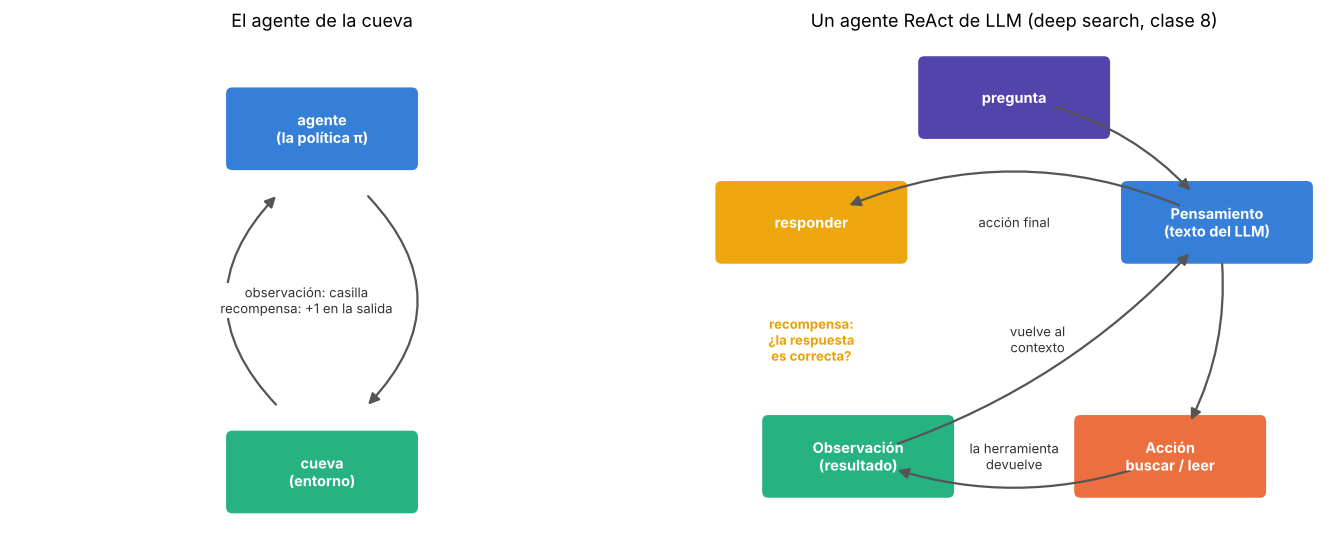

In [4]:
dibujar_ciclos()

| | Cueva (Q-learning) | Agente ReAct de LLM (*deep search*) |
|---|---|---|
| **Pensamiento** | no hay: mira su tabla Q | texto: "no lo sé, busco" |
| **Acción** | ↑ → ↓ ← | buscar, abrir un documento, responder |
| **Observación** | la casilla (y si tocó pared) | lo que devolvió la herramienta, sumado a todo lo anterior |
| **Recompensa** | +1 en la salida | ¿la respuesta es correcta? (− costo por paso) |
| **Episodio** | una partida | una investigación |

En la clase 8 resolvimos la versión chica de *deep search* como un MDP. Ahora hagamos lo contrario: pongamos un LLM **real** a jugar la cueva con el bucle ReAct.

### Paso 2 — La cueva en modo texto

El modelo tiene dos herramientas, igual que una persona que juega a oscuras:

- `mover(dirección)` con dirección `arriba`, `abajo`, `izquierda` o `derecha`: devuelve `"avancé."`, `"choqué con una pared."` o `"¡salí de la cueva!"`;
- `sentir()`: devuelve qué paredes hay alrededor (los "bigotes" de la clase 6).

No le decimos dónde está: como al jugador humano, solo le llega lo que devuelve cada herramienta. Así se ve una partida "a mano" y el pedido (*prompt*) que recibe el modelo:

In [5]:
demo = CaveEnv()
for txt in ["Acción: sentir()", "Acción: mover(arriba)", "Acción: mover(derecha)", "Acción: caminar al norte", "Acción: bailar"]:
    print(f"{txt:28s} → {ejecutar_accion(demo, txt)}")
print("\n----- prompt del sistema -----\n" + SISTEMA_REACT)

Acción: sentir()             → pared arriba y a la izquierda; libre a la derecha y abajo.
Acción: mover(arriba)        → choqué con una pared.
Acción: mover(derecha)       → avancé.
Acción: caminar al norte     → choqué con una pared.
Acción: bailar               → no entendí la acción: usá mover(dirección) o sentir().

----- prompt del sistema -----
Estás en una cueva a oscuras, en una grilla. No ves nada. Tu objetivo es encontrar la salida.
Herramientas:
- mover(dirección): dirección es arriba, abajo, izquierda o derecha. Responde "avancé" o "choqué con una pared".
- sentir(): tocás las paredes que tenés alrededor.
Reglas: si chocás, probá otra dirección. No vuelvas por donde viniste si hay otro camino libre.
Respondé SIEMPRE con exactamente dos líneas:
Pensamiento: <una oración corta>
Acción: <mover(dirección) o sentir()>
Ejemplo:
Pensamiento: Todavía no sé nada; toco las paredes.
Acción: sentir()
Observación: pared arriba y a la izquierda; libre a la derecha y abajo.
Pensamiento: A

El *parser* es **tolerante**: acepta `mover(derecha)`, `mover("derecha")` o "caminar al norte"; si no entiende, la observación lo dice y el paso cuenta igual. Con modelos chicos, leer bien la acción es la mitad del trabajo.

### Paso 3 — Cargar el modelo

`Qwen/Qwen2.5-0.5B-Instruct`: 500 millones de parámetros, abierto, sin cuenta ni token (≈ 1 GB la primera vez). Es el mismo generador de la clase 11.

In [6]:
llm, tok = cargar_llm("Qwen/Qwen2.5-0.5B-Instruct")

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✓ Qwen/Qwen2.5-0.5B-Instruct cargado en 2 s (cpu)


### Paso 4 — El agente ReAct juega

En cada paso el texto es: prompt del sistema + toda la traza hasta ahora + `Pensamiento:`. El modelo completa un pensamiento y una acción (generaciones cortas: a lo sumo 40 *tokens*), cortamos antes de que invente la observación, ejecutamos la acción en la cueva y pegamos la observación verdadera. Límite: 30 pasos (el camino más corto tiene 20).

Una decisión que hay que contar: con decodificación **codiciosa** (*greedy*, siempre la palabra más probable) este modelo entra enseguida en un bucle (en nuestras pruebas: `sentir()` 28 veces seguidas, o derecha–izquierda sin fin; lo ven en el ejercicio). Por eso acá muestreamos con **temperatura 0,7** y semilla fija; elegimos la semilla 1 porque su traza muestra más cosas. Con otra semilla, o en otra máquina, la traza cambia.

In [7]:
cueva_txt = CaveEnv()
traza = agente_react(cueva_txt, max_pasos=30, temperatura=0.7, semilla=1)
mostrar_traza(traza)
json.dump(traza, open("traza_react.json", "w"), ensure_ascii=False)   # la página web de la clase recorre esta traza

30 pasos en 179 s
[ 1] Pensamiento: Me encuentro en la cueva, pero no tengo un sentido visual.
     Acción: no pido ayuda
     Observación: no entendí la acción: usá mover(dirección) o sentir().
[ 2] Pensamiento: Tengo que buscar el nombre de la entrada para poder avanzar.
     Acción: sentir()
     Observación: pared arriba y a la izquierda; libre a la derecha y abajo.
[ 3] Pensamiento: A la derecha está libre.
     Acción: mover(derecha)
     Observación: avancé.
[ 4] Pensamiento: Sigo hacia la derecha.
     Acción: mover(derecha)
     Observación: avancé.
[ 5] Pensamiento: Todavía no sé nada; toco las paredes.
     Acción: sentir()
     Observación: pared arriba y abajo; libre a la derecha y a la izquierda.
[ 6] Pensamiento: A la izquierda está libre.
     Acción: mover(izquierda)
     Observación: avancé.
[ 7] Pensamiento: Sigue hacia arriba.
     Acción: mover(arriba)
     Observación: choqué con una pared.
[ 8] Pensamiento: Choqué; pruebo hacia abajo.
     Acción: mover(abajo)
  

### Paso 5 — Dónde anduvo

La trayectoria con `env.plot`, como siempre. Las × rojas son choques; los círculos, los lugares donde usó `sentir()`.

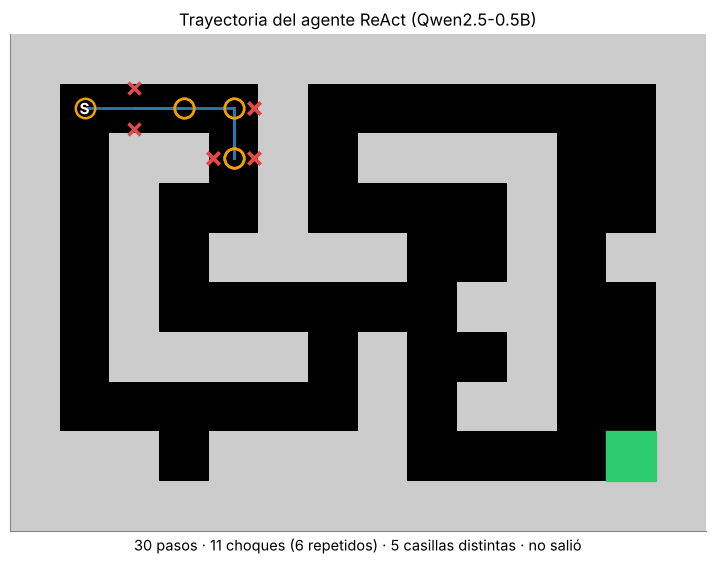

{'salio': False,
 'pasos': 30,
 'choques': 11,
 'choques_repetidos': 6,
 'distintas': 5,
 'sentir': 8,
 'no_entendidas': 1,
 'camino': [0, 1, 2, 1, 2, 3, 12, 3, 12, 3, 12]}

In [8]:
dibujar_react(traza)

### Paso 6 — Comparación honesta: ReAct vs. azar vs. Q-learning

Mismo límite de pasos para todos (30). El agente al azar juega 2000 partidas; Q-learning (clase 4) entrena 300 partidas y después juega con su política codiciosa.

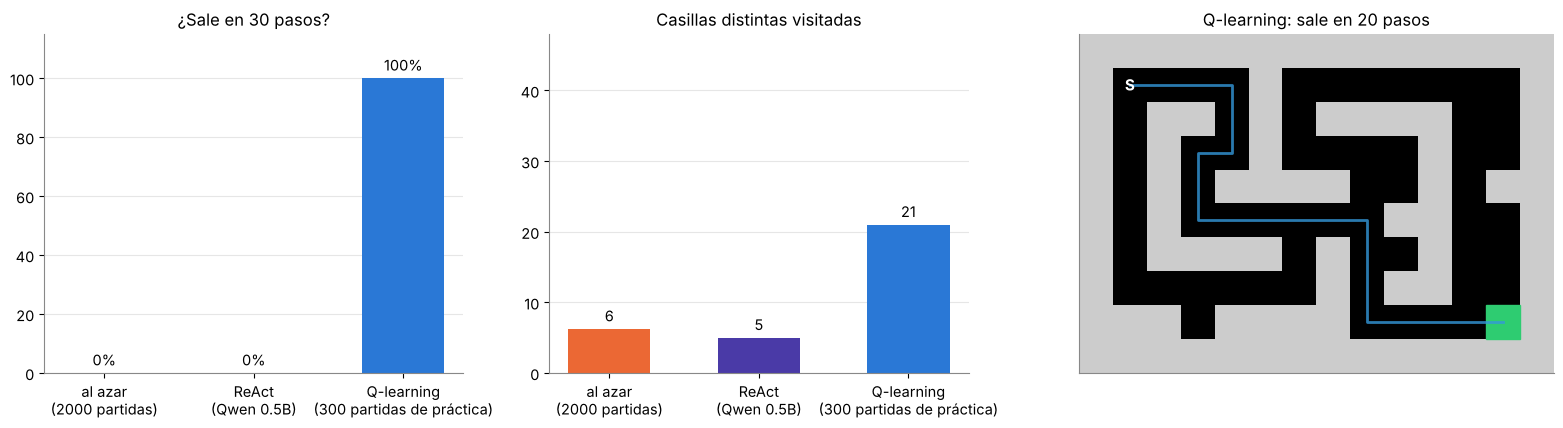

al azar:    sale el 0% de las veces · 6.2 casillas distintas · 7.8 choques repetidos por partida
ReAct:      no sale · 5 casillas distintas · 11 choques (6 repetidos) · sentir() 8 veces · 1 acciones no entendidas
Q-learning: sale en 20 pasos (el camino más corto tiene 20)


{'react': {'salio': False,
  'pasos': 30,
  'choques': 11,
  'choques_repetidos': 6,
  'distintas': 5,
  'sentir': 8,
  'no_entendidas': 1,
  'camino': [0, 1, 2, 1, 2, 3, 12, 3, 12, 3, 12]},
 'azar': (np.float64(0.0), np.float64(6.239), np.float64(7.826)),
 'q': 20}

In [9]:
comparar_agentes(traza, max_pasos=30)

**Lo que pasó en nuestra corrida.** En 30 pasos el agente ReAct no sale. Recorre 5 casillas distintas (el azar, 6 en promedio) y choca 11 veces; 6 de esos choques repiten uno que ya conocía (el azar repite unos 8 por partida). Desde el paso 13 queda yendo y viniendo entre dos casillas con el mismo ciclo: `sentir()` → "A la derecha está libre" → `mover(derecha)` → choca → prueba otra dirección.

Lo más llamativo: **el pensamiento contradice la observación**. En el paso 14 siente "pared a la derecha" y en el 15 escribe "A la derecha está libre". Y frases como "Todavía no sé nada; toco las paredes" o "Choqué; pruebo hacia abajo" son copias literales del ejemplo del prompt: el modelo imita la forma de la traza más que razonar sobre ella.

¿Por qué le va tan mal, si "piensa"?

1. **Memoria.** Su única memoria es el texto de la traza. Para saber dónde está tendría que ir sumando movimientos ("dos a la derecha, uno abajo") y armarse un mapa; nada de eso viene en las observaciones, y un modelo de 500 millones de parámetros no lo hace solo. Es historia vs. estado (clases 2 y 7): con la historia cruda, el estado hay que construirlo.
2. **Recompensa.** ReAct no aprende: los pesos no cambian y nunca ve una recompensa, así que la partida 100 sería igual de mala que la primera. Q-learning tampoco "piensa", pero guardó en su tabla lo que le enseñaron 300 partidas con recompensa; por eso sale en 20 pasos, el camino más corto.
3. **Tamaño.** Un modelo más grande seguiría mejor el formato y usaría mejor `sentir()`, pero los dos problemas de arriba siguen ahí. Los agentes de LLM en serio agregan memoria explícita (un mapa, notas) y se entrenan con RL (DeepSeek-R1, sección 4).

ReAct es una buena **forma** de ordenar el ciclo agente–entorno; no reemplaza lo que da la recompensa.

### ✍️ Ejercicio

La celda corre 12 pasos con decodificación codiciosa (`temperatura=0.0`) y dándole la posición: con `con_posicion=True` cada observación agrega la casilla, por ejemplo `"avancé. Estás en (fila 1, columna 2)."`, y el estado pasa a ser Markov (clase 2). ¿Sale del bucle? Prueben después `temperatura=0.7` con otras semillas, y `ventana=3` (el modelo solo ve los últimos 3 pasos: menos memoria, ¿más vueltas?). Cada corrida tarda uno o dos minutos en CPU.

12 pasos en 67 s
[ 1] Pensamiento: Avanza hacia el lado derecho.
     Acción: mover(derecha)
     Observación: avancé. Estás en (fila 1, columna 2).
[ 2] Pensamiento: Prueba ahora hacia el lado izquierdo.
     Acción: mover(izquierda)
     Observación: avancé. Estás en (fila 1, columna 1).
[ 3] Pensamiento: Ahora prueba hacia el lado superior.
     Acción: mover(arriba)
     Observación: choqué con una pared. Estás en (fila 1, columna 1).
[ 4] Pensamiento: Choqué; pruébalo ahora hacia abajo.
     Acción: mover(abajo)
     Observación: avancé. Estás en (fila 2, columna 1).
[ 5] Pensamiento: Prueba ahora hacia el lado inferior.
     Acción: mover(derecha)
     Observación: choqué con una pared. Estás en (fila 2, columna 1).
[ 6] Pensamiento: Choqué; pruébalo ahora hacia el lado izquierdo.
     Acción: mover(izquierda)
     Observación: choqué con una pared. Estás en (fila 2, columna 1).
[ 7] Pensamiento: Choqué; pruébalo ahora hacia el lado superior.
     Acción: mover(arriba)
     Obser

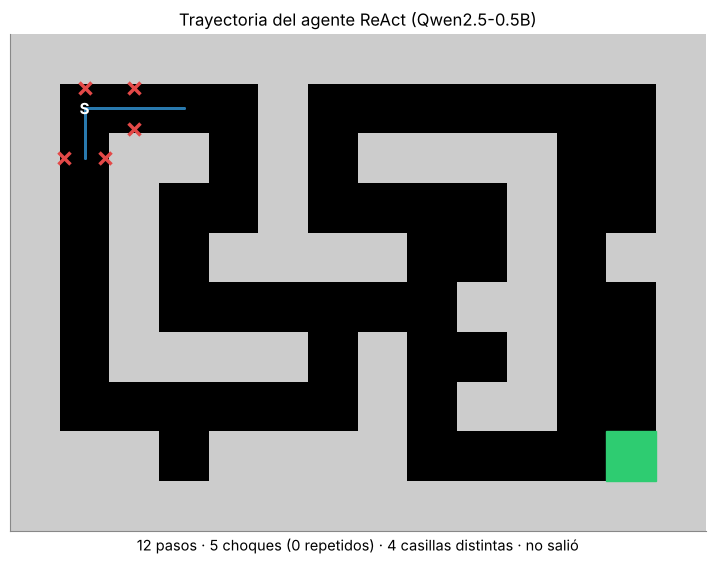

{'salio': False,
 'pasos': 12,
 'choques': 5,
 'choques_repetidos': 0,
 'distintas': 4,
 'sentir': 0,
 'no_entendidas': 0,
 'camino': [0, 1, 0, 11, 0, 1, 2, 1]}

In [10]:
# TODO: probar temperatura=0.7 (y otras semillas), con_posicion=False/True y ventana=None/3
traza_ej = agente_react(CaveEnv(), max_pasos=12, temperatura=0.0, semilla=0, con_posicion=True, ventana=None)
mostrar_traza(traza_ej)
dibujar_react(traza_ej)

Liberamos la memoria del modelo antes de seguir.

In [11]:
liberar_llm()

Modelo liberado.


## 2. El feed como un MDP con γ ≈ 0

En el bucle ReAct, el feed es un agente sin pensamiento en voz alta: la **acción** es qué publicaciones mostrar y la **observación** llega recién mañana (¿el usuario vuelve?). Y a diferencia de la cueva, no se puede ensayar un millón de veces.

### Paso 1 — Cómo se ordena un feed (según lo publicado)

Meta publicó descripciones generales de cómo ordena el feed de Facebook e Instagram (por ejemplo, sus *system cards* de 2023). El esquema es:

1. juntar **candidatos** (miles de publicaciones posibles);
2. redes neuronales **multitarea** (*multi-task*) predicen, para cada candidato, varias probabilidades: P(verlo), P(like), P(compartir), P(guardar), P(ocultarlo)…;
3. un **puntaje ponderado**: suma de cada probabilidad por un peso (ocultar resta);
4. **ordenar** por puntaje.

Abajo, un ejemplo de juguete con números **inventados**.

> ⚠️ Qué usa hoy cada plataforma no es público, y lo publicado puede estar desactualizado. Lo usamos como modelo mental, no como descripción exacta.

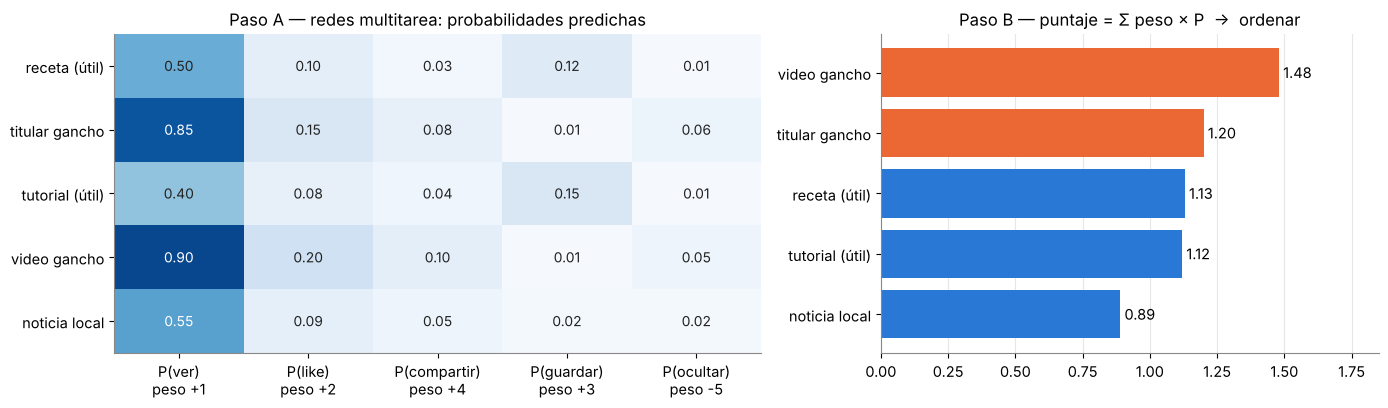

Orden del feed: video gancho > titular gancho > receta (útil) > tutorial (útil) > noticia local


In [12]:
POSTS = ["receta (útil)", "titular gancho", "tutorial (útil)", "video gancho", "noticia local"]
NOMBRES_P = ["P(ver)", "P(like)", "P(compartir)", "P(guardar)", "P(ocultar)"]
PROBS = [[0.50, 0.10, 0.03, 0.12, 0.01],     # inventados
         [0.85, 0.15, 0.08, 0.01, 0.06],
         [0.40, 0.08, 0.04, 0.15, 0.01],
         [0.90, 0.20, 0.10, 0.01, 0.05],
         [0.55, 0.09, 0.05, 0.02, 0.02]]
PESOS = [1.0, 2.0, 4.0, 3.0, -5.0]
dibujar_ranking(POSTS, PROBS, PESOS, NOMBRES_P)

Esto es **aprendizaje supervisado**: cada red predice algo que se puede verificar en la sesión (¿dio like o no?). En lenguaje de RL es una política **miope**: maximiza la recompensa inmediata, es decir, un MDP con **γ = 0**. No se pregunta qué le pasa al usuario mañana.

### Paso 2 — Un usuario de juguete

Construimos un simulador mínimo. El usuario tiene **intereses ocultos** y un estado oculto de **satisfacción** (0 a 10, empieza en 5). Cada día el sistema le arma el feed de un tipo:

- **gancho** (*clickbait*): muchos clics hoy, pero la satisfacción baja un nivel (con prob. 60%);
- **útil** (lo que coincide con sus intereses): menos clics hoy, pero la satisfacción sube un nivel (con prob. 60%).

Suponemos que el sistema ya sabe qué es "útil" para cada usuario (eso es lo que intentan estimar las redes del paso 1). La probabilidad de que vuelva mañana depende de la satisfacción.

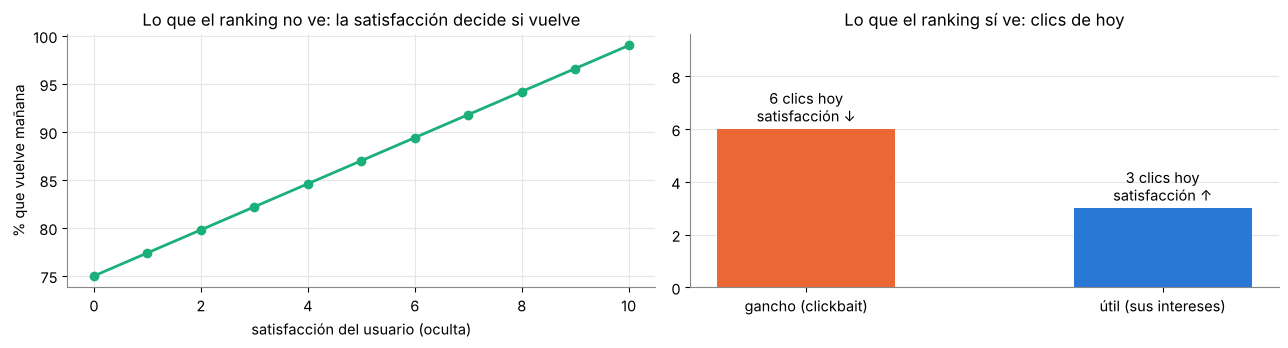

In [13]:
mostrar_usuario()

### Paso 3 — Resolver el MDP con distintos γ

Estado = satisfacción (más un estado "se fue", absorbente). Acción = gancho o útil. Recompensa = clics del día. Lo resolvemos con iteración de valor (*value iteration*, clase 3) para varios factores de descuento γ.

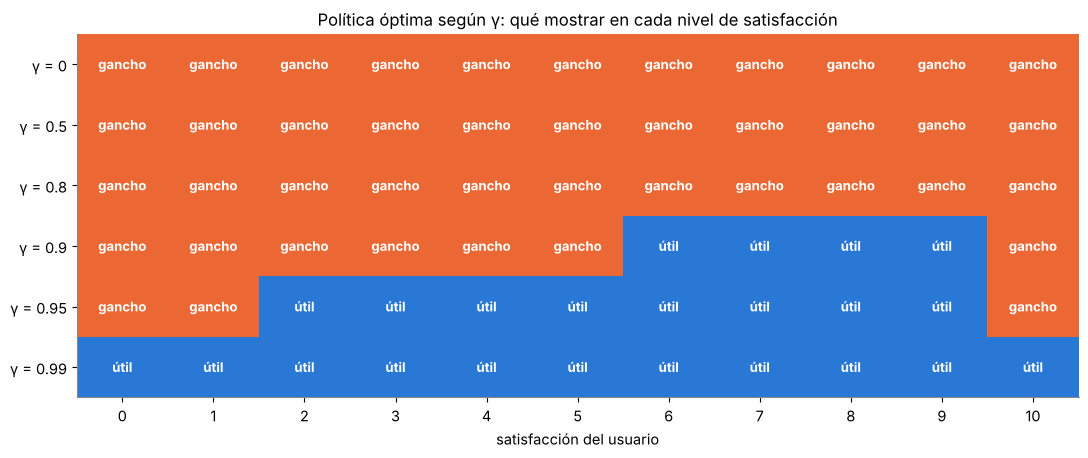

In [14]:
GAMMAS = [0, 0.5, 0.8, 0.9, 0.95, 0.99]
pols_feed = politicas_feed(GAMMAS)

Con γ = 0 (el ranking miope) la respuesta es **gancho siempre**. Recién cuando el futuro pesa (γ ≥ 0.9) aparece el contenido útil, primero en los usuarios satisfechos y con γ alto en casi todos.

Dos detalles incómodos que vale la pena mirar:
- con satisfacción 10 (y γ = 0.9 o 0.95) la política vuelve al gancho: el usuario ya no puede estar más contento, así que "se cobra" un poco;
- con γ = 0.95, a los usuarios muy hartos (0 y 1) también les muestra gancho: el algoritmo calcula que es difícil recuperarlos y prefiere exprimirlos. **Optimizar la recompensa no es lo mismo que cuidar al usuario.**

### Paso 4 — Clics de hoy vs. días que el usuario sigue volviendo

Simulamos 5000 usuarios durante 90 días con cada política.

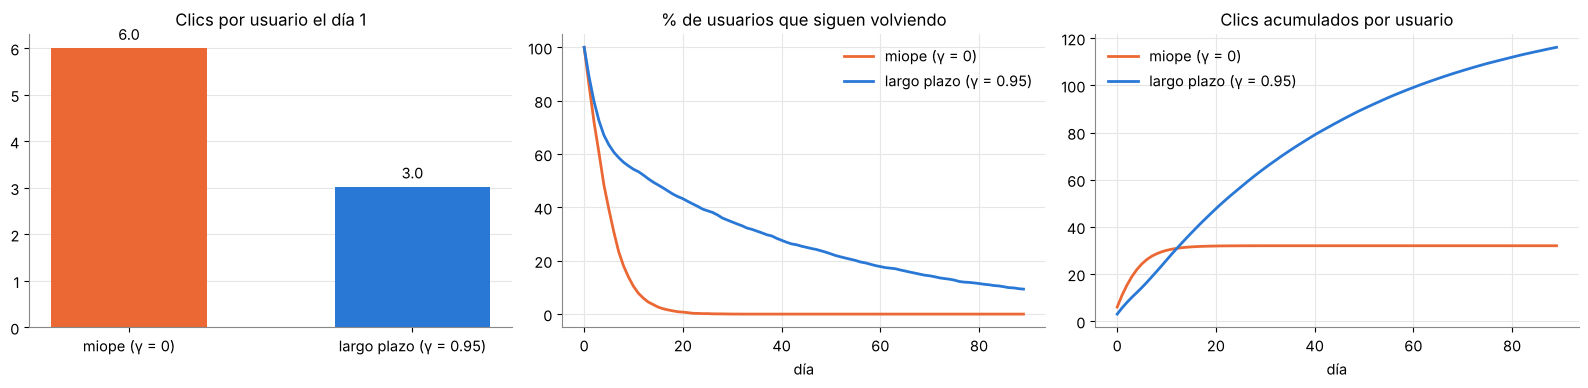

miope (γ = 0)          clics día 1:  6.0 · activos el día 30:  0.0% · clics en 90 días:  32.0
largo plazo (γ = 0.95) clics día 1:  3.0 · activos el día 30: 34.5% · clics en 90 días: 116.1


In [15]:
res_feed = comparar_feeds({"miope (γ = 0)": pols_feed[0], "largo plazo (γ = 0.95)": pols_feed[0.95]})

La política miope gana el día 1 (6.0 clics contra 3.0), pero el día 30 ya no le queda ningún usuario (0.0%), mientras que la de largo plazo conserva el 34.5%. Antes de las dos semanas las curvas de clics acumulados se cruzan, y a los 90 días la de largo plazo junta **116.1 clics por usuario contra 32.0**: más del triple, mostrando la mitad de clics por día.

Es el **reward hacking** del tutor de la clase 8: el tutor que solo daba sumas maximizaba aciertos y no aprendizaje; el feed miope maximiza clics y no que el usuario quiera volver. Por eso hay trabajos que pasaron a RL para recomendaciones (por ejemplo, REINFORCE en YouTube, Chen et al., 2019): optimizar el retorno, no el clic.

Pero hay un problema práctico: en esta celda **inventamos el simulador**. Una plataforma real no tiene `feed_mdp()`: solo tiene los registros de lo que su política actual mostró y de lo que los usuarios hicieron.

### ✍️ Ejercicio

1. Bajen los clics del gancho a `4.0`. ¿Para qué γ empieza a convenir el contenido útil?
2. Hagan que el gancho dañe menos: `P_CAMBIO = 0.3`. ¿Cambia la política de largo plazo?

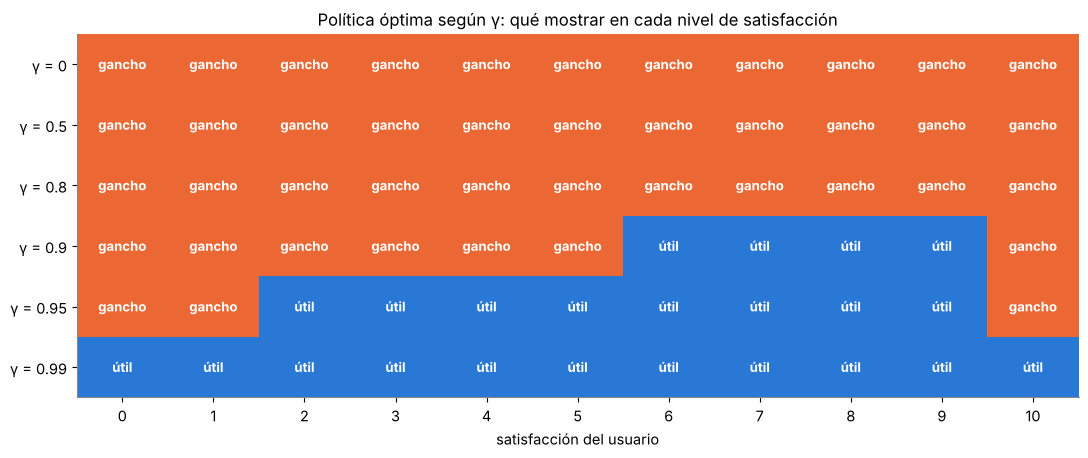

In [16]:
# TODO: cambiar los clics del gancho y/o P_CAMBIO y volver a ejecutar
CLICS = np.array([6.0, 3.0])     # [gancho, útil]
P_CAMBIO = 0.6
_ = politicas_feed(GAMMAS)
CLICS, P_CAMBIO = np.array([6.0, 3.0]), 0.6   # restaurar para el resto del notebook

## 3. RL sin simulador: ReAgent y la evaluación contrafactual

En 2018 Facebook publicó **Horizon** (Gauci et al., arXiv:1811.00260), su plataforma de RL aplicado, después renombrada **ReAgent**. Estaba pensada para problemas con **muchos datos, respuesta lenta y sin simulador**. Los usos en producción que se reportaron ese año (VentureBeat, 2018): decidir **cuándo mandar notificaciones**, las sugerencias del asistente **M en Messenger** y el **bitrate de los videos 360°**.

En términos del bucle ReAct: las acciones y observaciones **ya pasaron** y quedaron en registros. La pieza clave no era el algoritmo de aprendizaje sino la **evaluación contrafactual de políticas** (*counterfactual / off-policy policy evaluation*):

> ¿Cuánto rendiría una política **nueva** si la pusiéramos en producción, usando **solo los registros** de la política **vieja**?

Si la respuesta es "mal", no se lanza. Lo probamos en la cueva, donde sí podemos hacer trampa y comparar con el valor verdadero.

### Paso 1 — Los registros de la política vieja

La política vieja (o **de comportamiento**, *behavior policy*) $b$ juega la acción óptima con probabilidad $\alpha = 0.6$ y una acción al azar el 40% restante. Es estocástica y **conocemos sus probabilidades**: la acción óptima tiene $b = 0.6 + 0.4/4 = 0.7$ y cada una de las otras $0.1$. De cada partida guardamos $(s, a, r, b(a|s))$.

Recompensa: +1 al salir y nada más; γ = 0.95; como máximo 60 pasos. Así el valor desde S es fácil de leer: salir en $k$ pasos vale $0.95^{k-1}$ (el camino más corto, de 20 pasos, vale $0.95^{19} \approx 0.377$), y no salir vale 0.

500 partidas registradas · salieron de la cueva: 100% · retorno medio: +0.190 · pasos registrados: 17184


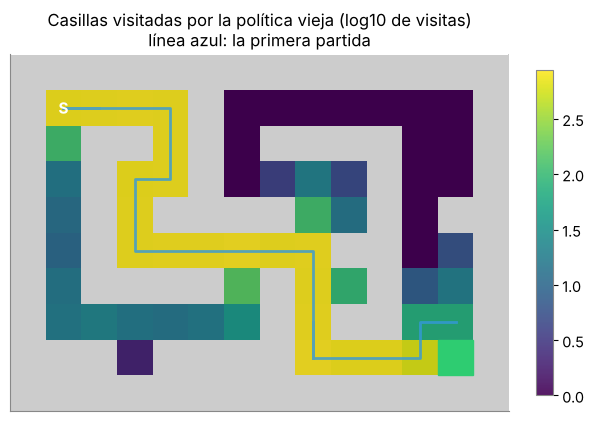

In [17]:
ALPHA_VIEJA = 0.6
b = politica_mezcla(ALPHA_VIEJA)
registro = jugar(b, N=500, seed=0)
S, A, Rw, M = registro
salieron = Rw.max(1) == 1
print(f"500 partidas registradas · salieron de la cueva: {100 * salieron.mean():.0f}% · "
      f"retorno medio: {retorno(Rw).mean():+.3f} · pasos registrados: {M.sum()}")
visitas = mapa_cobertura(registro, "Casillas visitadas por la política vieja (log10 de visitas)\nlínea azul: la primera partida")
plt.show()

El color es cuántas veces pasó la política vieja por cada casilla (escala log): el corredor hacia la salida está muy transitado y los rincones, casi nada.

### Paso 2 — Repesar el pasado

Queremos evaluar una política nueva $\pi$ que juega la óptima con otra probabilidad: $\alpha = 0.7$ (**parecida** a la vieja) o $\alpha = 0.95$ (**lejana**). La idea del **muestreo por importancia** (*importance sampling*, IS; Sutton y Barto, sección 5.5): a cada partida registrada le damos un peso según cuánto más (o menos) probable habría sido bajo la política nueva. Si la nueva habría jugado esa partida con el doble de probabilidad, la partida cuenta doble.

Veamos primero cómo son esos pesos.

α = 0.7: peso mediano 0.64, peso máximo 4.8, las 10 partidas más pesadas (de 500) suman el 8% del peso total
α = 0.95: peso mediano 1.9e-06, peso máximo 12.5, las 10 partidas más pesadas (de 500) suman el 81% del peso total


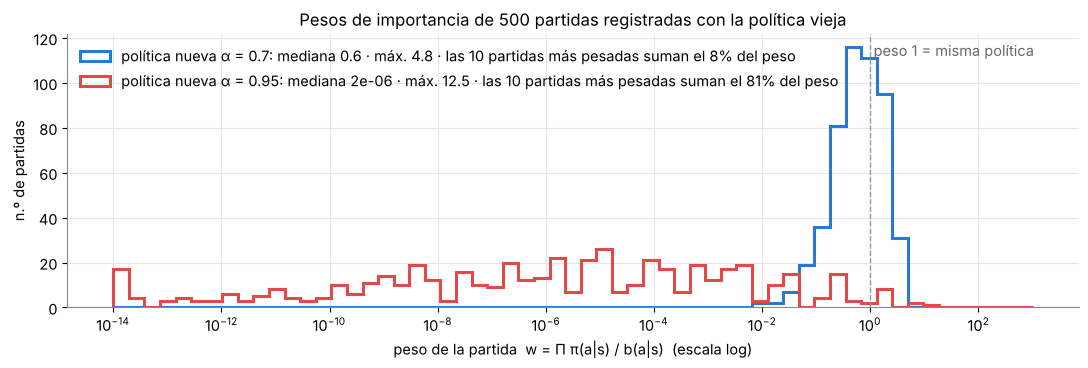

In [18]:
mostrar_pesos(b, alphas=[0.7, 0.95])

- Con la política **parecida** ($\alpha = 0.7$, azul) los pesos se amontonan cerca de 1 (mediana 0.64, máximo 4.8) y las 10 partidas más pesadas suman solo el 8% del peso: **todas las partidas aportan**.
- Con la **lejana** ($\alpha = 0.95$, rojo) la mediana es 0.0000019 y las 10 partidas más pesadas suman el **81%** del peso total. La estimación depende de un puñado de partidas, las que por casualidad jugaron casi siempre la acción óptima. Otro registro, otro puñado, otro resultado: eso es **varianza**.

Ahora sí, las ecuaciones. Para una partida con pasos $t = 0, \dots, T$:

$$\rho_t = \frac{\pi(a_t|s_t)}{b(a_t|s_t)} \qquad w = \prod_{t} \rho_t \qquad G = \sum_t \gamma^t r_t$$

| Estimador | Fórmula | Idea |
|---|---|---|
| **IS** (por trayectoria) | $\frac{1}{N}\sum_i w_i G_i$ | promedio repesado; sin sesgo |
| **WIS** (IS ponderado) | $\sum_i w_i G_i \,/\, \sum_i w_i$ | normaliza por la suma de pesos; con sesgo pero estable |
| **IS por decisión** (*per-decision*, Precup, Sutton y Singh, 2000) | $\frac{1}{N}\sum_i \sum_t \gamma^t r_{i,t} \prod_{k\le t}\rho_{i,k}$ | cada recompensa usa solo los pesos **hasta ese paso**; ayuda cuando la recompensa llega por el camino |
| **Método directo** (DM) | aprender $\hat P, \hat R$ de los registros y evaluar $\pi$ en ese modelo (clase 3) | no usa pesos; depende de qué tan bien cubren los datos |

En el método directo, un par (casilla, acción) que **nunca** aparece en los registros se supone pared: el agente se queda donde está, como en el juego cuando todavía no tocamos esa pared.

En la cueva toda la recompensa llega **al salir**, así que IS por decisión le pone a esa recompensa el mismo peso completo que IS: los dos dan **exactamente lo mismo**. Lo comprobamos y desde acá seguimos con tres. (IS por decisión rinde cuando hay recompensas a lo largo del camino, como los clics diarios del feed: un clic del día 3 no tiene por qué cargar con lo que se decidió el día 40.)

In [19]:
e = estimar(registro, politica_mezcla(0.95), b)
print(f"α = 0.95 con las 500 partidas → IS: {e['IS']:.6f} · IS por decisión: {e['IS por decisión']:.6f}")

α = 0.95 con las 500 partidas → IS: 0.118005 · IS por decisión: 0.118005


### Paso 3 — Política parecida vs. política lejana

Para cada cantidad de partidas registradas $N$ repetimos la estimación 100 veces con registros distintos. El **valor verdadero** lo calculamos con el modelo real de la cueva (lo que en el mundo real **no** tenemos). Primero comprobamos que es lo mismo que jugar la política nueva muchísimas veces.

In [20]:
pi_lejana = politica_mezcla(0.95)
mc = retorno(jugar(pi_lejana, N=20000, seed=99)[2]).mean()
print(f"Valor de la política α = 0.95: con el modelo {valor_verdadero(pi_lejana):.4f} · jugándola 20000 veces {mc:.4f}")

Valor de la política α = 0.95: con el modelo 0.3574 · jugándola 20000 veces 0.3574


Coinciden. Ahora, los estimadores, que solo ven los registros de la política vieja.

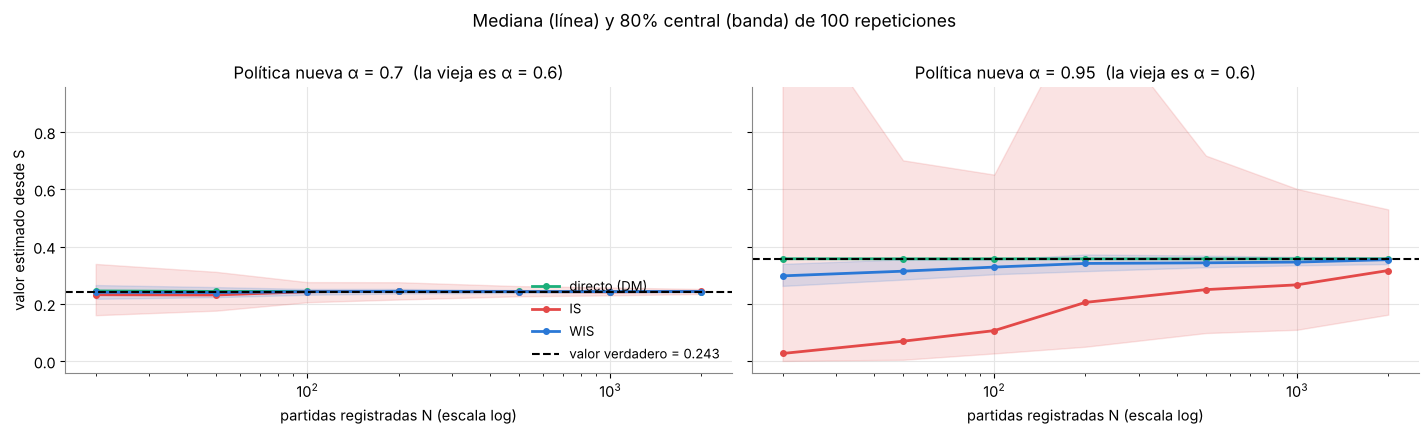

α = 0.7 · valor verdadero +0.243 · con N = 2000:
    directo (DM)     media +0.243   desvío 0.000
    IS               media +0.244   desvío 0.007
    WIS              media +0.243   desvío 0.002
α = 0.95 · valor verdadero +0.357 · con N = 2000:
    directo (DM)     media +0.357   desvío 0.000
    IS               media +0.342   desvío 0.145
    WIS              media +0.353   desvío 0.009


In [21]:
Ns = [20, 50, 100, 200, 500, 1000, 2000]
tabla_conv = convergencia(b, alphas=[0.7, 0.95], Ns=Ns)

- **Política parecida** (izquierda): los tres estimadores se pegan al valor verdadero (0.243) y la banda se angosta al crecer $N$; con 2000 partidas el desvío es 0.007 para IS y 0.002 para WIS. Cuando las políticas se parecen, **evaluar con registros funciona**.
- **Política lejana** (derecha), **IS** (rojo): banda enorme y una mediana muy por debajo del valor verdadero. La mayoría de las veces subestima, y de vez en cuando una partida con peso gigante lo dispara para arriba. En promedio acierta (no tiene sesgo: media 0.342 contra 0.357 con $N = 2000$), pero con un desvío de 0.145, el 40% del valor.
- **WIS** (azul): estable pero **sesgado**. Con pocas partidas queda claramente por debajo del valor verdadero; el sesgo se achica al crecer $N$ (0.353 ± 0.009 con 2000).
- **Método directo** (verde): acierta en los dos casos, porque la política vieja ($\alpha = 0.6$) explora lo suficiente como para cubrir el camino.

### Paso 4 — El "slider": alejar la política nueva

Fijamos $N = 500$ partidas y movemos el $\alpha$ de la política nueva de 0 (siempre al azar) a 0.99 (casi siempre la óptima). La línea punteada vertical es la política vieja ($\alpha = 0.6$).

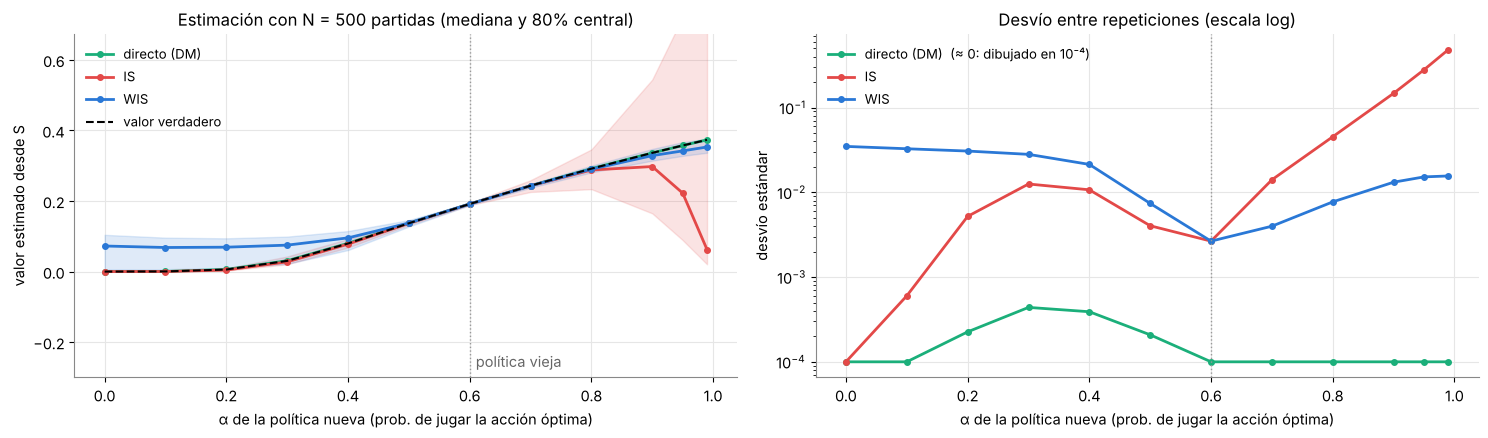

 α nueva | verdadero |   directo (DM)   |        IS        |        WIS       
  0.00  |  +0.000   | +0.000 ±  0.000 | +0.000 ±  0.000 | +0.064 ±  0.035 
  0.10  |  +0.000   | +0.000 ±  0.000 | +0.000 ±  0.001 | +0.059 ±  0.033 
  0.20  |  +0.006   | +0.006 ±  0.000 | +0.006 ±  0.005 | +0.059 ±  0.031 
  0.30  |  +0.030   | +0.031 ±  0.000 | +0.031 ±  0.013 | +0.067 ±  0.028 
  0.40  |  +0.080   | +0.080 ±  0.000 | +0.080 ±  0.011 | +0.090 ±  0.021 
  0.50  |  +0.137   | +0.137 ±  0.000 | +0.137 ±  0.004 | +0.137 ±  0.007 
  0.60  |  +0.192   | +0.192 ±  0.000 | +0.191 ±  0.003 | +0.191 ±  0.003 
  0.70  |  +0.243   | +0.243 ±  0.000 | +0.242 ±  0.014 | +0.243 ±  0.004 
  0.80  |  +0.292   | +0.292 ±  0.000 | +0.290 ±  0.045 | +0.290 ±  0.008 
  0.90  |  +0.336   | +0.336 ±  0.000 | +0.328 ±  0.147 | +0.330 ±  0.013 
  0.95  |  +0.357   | +0.357 ±  0.000 | +0.337 ±  0.279 | +0.346 ±  0.015 
  0.99  |  +0.373   | +0.373 ±  0.000 | +0.334 ±  0.483 | +0.355 ±  0.016 


In [22]:
ALPHAS_NUEVAS = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99]
verdad_b, res_b = barrido(b, ALPHAS_NUEVAS, N=500)

- **Cerca de la política vieja** ($\alpha$ entre 0.5 y 0.7) los tres estimadores coinciden con el valor verdadero.
- **Hacia la derecha**, el desvío de IS crece casi en línea recta en escala log, o sea **exponencialmente**: 0.014 en $\alpha = 0.7$, 0.147 en 0.9 y 0.483 en 0.99, más que el propio valor (0.373). WIS se queda en ≈ 0.015 a cambio de un sesgo chico (0.355 contra 0.373 en $\alpha = 0.99$).
- **Hacia la izquierda** la política nueva casi nunca sale de la cueva: el valor verdadero es ≈ 0 e IS también da ≈ 0 (no hay recompensa que inflar). Acá se ve el **sesgo de WIS**: da 0.064 cuando el verdadero es 0.000. WIS es un promedio ponderado de los retornos registrados, y como **todas** las partidas registradas salieron de la cueva, nunca puede dar 0.
- **El método directo** acierta en todo el rango: con 500 partidas de una política vieja que explora, el modelo aprendido de la cueva es casi perfecto.

### Paso 5 — El horizonte largo también hace explotar a IS

El peso $w$ es un **producto** con un factor por paso: cuantos más pasos tiene la partida, más extremo se vuelve. Para verlo, arrancamos las partidas (de la vieja y de la nueva) en casillas del camino óptimo cada vez más lejos de la salida, con la política nueva $\alpha = 0.95$.

 2 pasos hasta la salida · valor verdadero 0.944 · error típico relativo: directo (DM) 0% · IS 4% · WIS 0%


 5 pasos hasta la salida · valor verdadero 0.804 · error típico relativo: directo (DM) 0% · IS 8% · WIS 0%


10 pasos hasta la salida · valor verdadero 0.613 · error típico relativo: directo (DM) 0% · IS 18% · WIS 1%


15 pasos hasta la salida · valor verdadero 0.468 · error típico relativo: directo (DM) 0% · IS 45% · WIS 2%


20 pasos hasta la salida · valor verdadero 0.357 · error típico relativo: directo (DM) 0% · IS 79% · WIS 4%


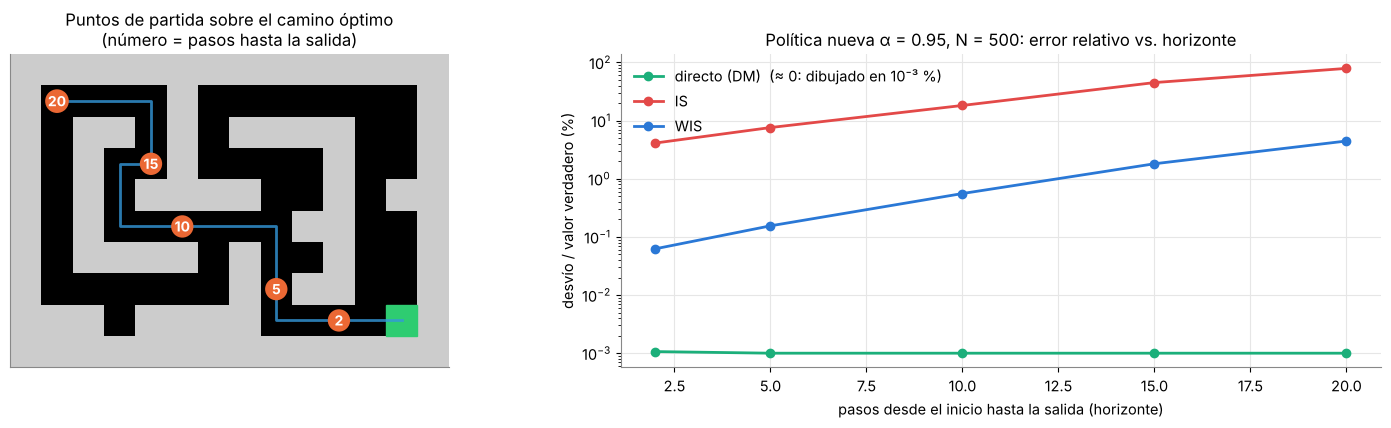

In [23]:
horizonte(b, alpha_nueva=0.95, distancias=[2, 5, 10, 15, 20])

Con la misma política nueva, el error relativo de IS pasa de **4%** arrancando a 2 pasos de la salida a **79%** arrancando a 20 pasos: en escala log es casi una recta, crecimiento exponencial con el horizonte. WIS también crece (de menos de 1% a 4%) pero mucho más lento, y el método directo ni se entera (no usa pesos).

**En una frase:** IS no tiene sesgo, pero su varianza crece **exponencialmente** con la distancia entre políticas y con el largo del horizonte; WIS cambia un poco de sesgo por mucha estabilidad; el método directo es excelente **mientras los datos cubran lo que la política nueva va a hacer**. Esto último es lo que probamos ahora.

### Paso 6 — El método directo depende de la cobertura

Probamos una política nueva **más exploradora** ($\alpha = 0.3$) con registros de dos políticas viejas: la de antes ($\alpha = 0.6$) y una casi determinística ($\alpha = 0.95$), que casi no se sale del camino.

política vieja α = 0.6: método directo con N = 10: +0.048, con N = 1000: +0.030  (verdadero +0.030)


política vieja α = 0.95: método directo con N = 10: +0.114, con N = 1000: +0.033  (verdadero +0.030)


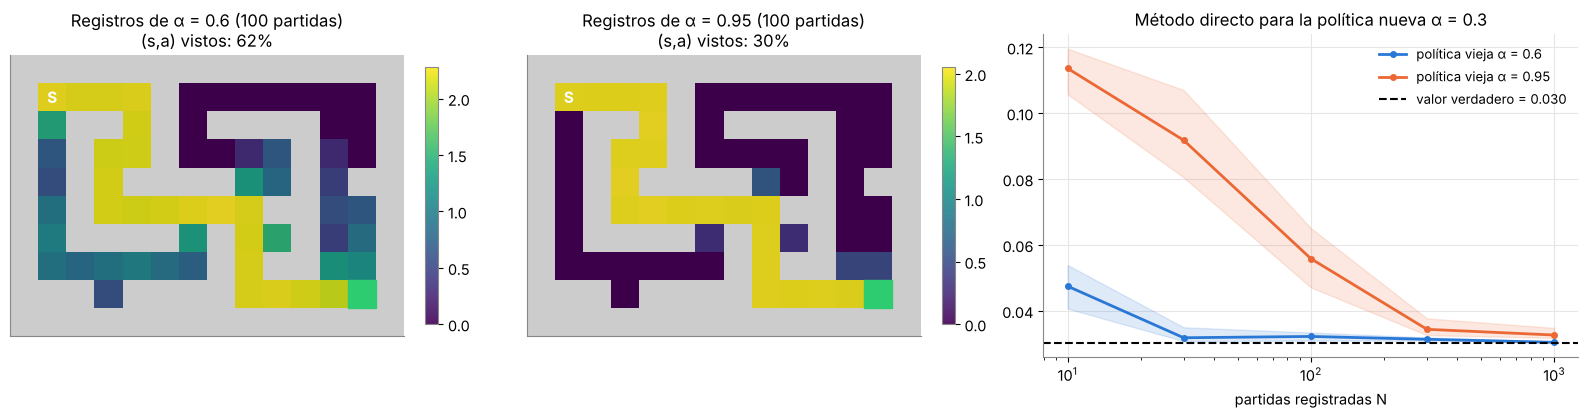

In [24]:
directo_vs_cobertura(alphas_viejas=[0.6, 0.95], alpha_nueva=0.3, Ns=[10, 30, 100, 300, 1000])

- Con registros de la política vieja **exploradora** ($\alpha = 0.6$; con 100 partidas vio el 62% de los pares casilla–acción) el método directo acierta casi enseguida: 0.048 con 10 partidas y 0.030 con 1000 (verdadero: 0.030).
- Con registros de la **casi determinística** ($\alpha = 0.95$; 30% de los pares vistos), el modelo aprendido está lleno de **paredes inventadas**: donde la política nueva se desviaría y se perdería, en el modelo choca y se queda en el camino. Por eso **sobreestima**: 0.114 con 10 partidas, casi 4 veces el valor verdadero, y necesita cientos de partidas para acercarse (0.033 con 1000).
- Fíjense que la banda es angosta: el método directo tiene poca varianza, **se equivoca con confianza**.

Lección para el mundo real: **si la política vieja nunca explora, no hay estimador que salve la evaluación** (IS explota y el método directo inventa). Por eso los sistemas como ReAgent registran políticas **estocásticas** junto con sus probabilidades: un poco de exploración hoy es lo que permite evaluar mañana.

### ✍️ Ejercicio

1. Muevan `ALPHA_NUEVA_EJ` entre `0.7` y `0.99`. ¿Desde qué valor el desvío de IS pasa a ser más grande que el propio valor?
2. Cambien `ALPHA_VIEJA_EJ = 0.85` (registros de una política vieja más parecida a la nueva). ¿Qué le pasa a IS? ¿Y a la cobertura que necesita el método directo?

In [25]:
# TODO: cambiar la política nueva y/o la vieja y volver a ejecutar
ALPHA_NUEVA_EJ = 0.95
ALPHA_VIEJA_EJ = 0.6
b_ej, pi_ej = politica_mezcla(ALPHA_VIEJA_EJ), politica_mezcla(ALPHA_NUEVA_EJ)
est = repetir(b_ej, pi_ej, N=500, reps=50, seed=7)
print(f"valor verdadero {valor_verdadero(pi_ej):.3f} (α nueva = {ALPHA_NUEVA_EJ}, α vieja = {ALPHA_VIEJA_EJ}, N = 500)")
for k, nombre in enumerate(ESTIMADORES):
    print(f"   {nombre:14s} {np.nanmean(est[:, k]):.3f} ± {np.nanstd(est[:, k]):.3f}")

valor verdadero 0.357 (α nueva = 0.95, α vieja = 0.6, N = 500)
   directo (DM)   0.357 ± 0.000
   IS             0.333 ± 0.304
   WIS            0.347 ± 0.014


### Paso 7 — RL offline: aprender solo con los registros

Evaluar es la mitad del problema. La otra mitad es **aprender** una política nueva sin jugar: RL *offline* (o *batch*). La versión más directa es correr Q-learning (clase 4) una y otra vez sobre el registro fijo, como un *replay buffer* que nunca se renueva (*fitted Q iteration*).

Usamos 100 partidas de la política vieja. Arrancamos la tabla Q con valores arbitrarios, como una red neuronal que da *algo* para entradas que nunca vio. Comparamos dos versiones:

- **ingenua**: el objetivo de Bellman usa $\max_{a'} Q(s', a')$ sobre **todas** las acciones;
- **conservadora**: el máximo solo sobre acciones que **aparecen en los registros** (la idea de métodos como BCQ o CQL).

En cada casilla, verde = siguiendo esa política desde ahí se llega a la salida; rojo = no. Las flechas son la política aprendida.

Q offline ingenuo      ¿sale desde S? no · sale desde  17% de las casillas visitadas y desde   6% de las 18 nunca visitadas · elige una acción que no figura en los registros en 12% de las visitadas
Q offline conservador  ¿sale desde S? sí · sale desde 100% de las casillas visitadas y desde  11% de las 18 nunca visitadas · elige una acción que no figura en los registros en 0% de las visitadas


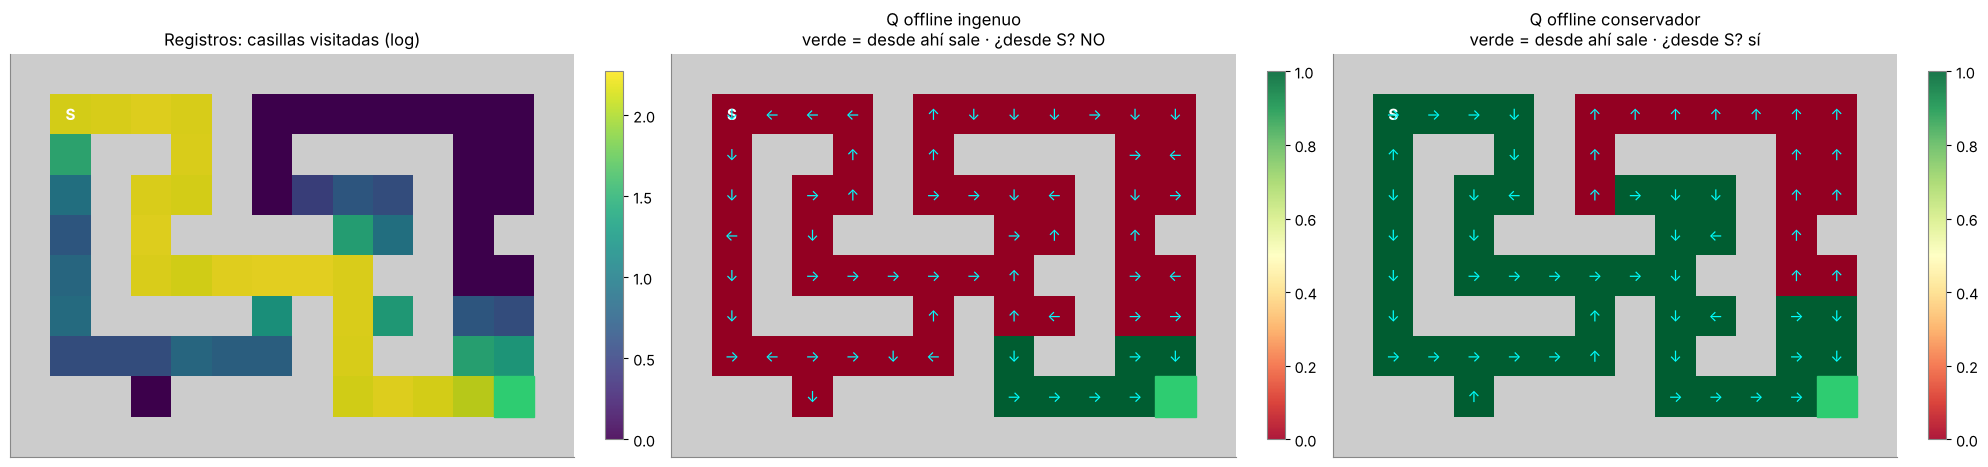

In [26]:
registro_100 = jugar(b, N=100, seed=5)
comparar_offline(registro_100)

- El **Q ingenuo no sale ni desde S**, la casilla con más datos: llega a la salida solo desde el 17% de las casillas visitadas. Elige directamente una acción que no figura en los registros solo en el 12% de esas casillas, pero alcanza: esos valores inventados se propagan por Bellman a las vecinas (el objetivo usa el máximo) y arrastran a la política hacia ellos.
- El **Q conservador** sale desde el 100% de las casillas visitadas, y desde S. En las 18 casillas que nunca aparecieron en los registros sale solo desde el 11%: ahí no tiene información.

Es el **cambio de distribución** (*distribution shift*): la política aprendida elige acciones (o llega a lugares) que los datos nunca mostraron, y ahí los valores de Q son inventados. Q-learning, que siempre elige el máximo, se enamora justamente de esos errores. La versión conservadora no hace magia: donde no hay datos tampoco sabe qué hacer, pero al menos no apuesta a lo que no vio.

## 4. De ReAgent a Pearl y a los LLM

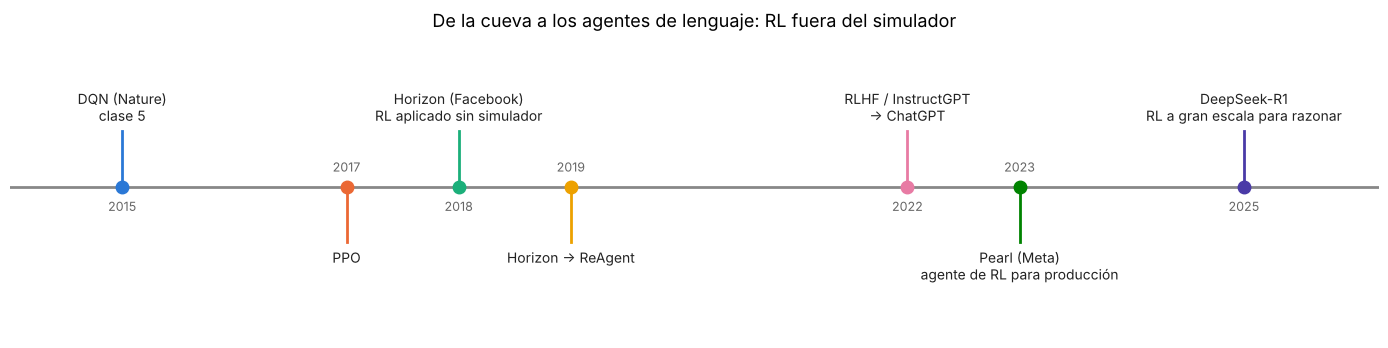

In [27]:
linea_de_tiempo()

- El repositorio de **ReAgent** está archivado y su README recomienda **Pearl** (Meta; Zhu et al., *Pearl: A Production-Ready Reinforcement Learning Agent*, arXiv:2312.03814). Los problemas son los mismos de esta clase, ahora empaquetados como **agente**: exploración, evaluación offline, aprendizaje con registros y **seguridad** (no probar cualquier cosa con usuarios reales).
- **RLHF** (Ouyang et al., 2022, la receta de ChatGPT que vimos en la clase 8): el modelo de lenguaje es un agente cuya **acción es el próximo texto** y cuya recompensa sale de un modelo entrenado con preferencias humanas.
- **DeepSeek-R1** (2025) mostró que RL a gran escala, con recompensas verificables y sin ajuste supervisado previo, hace aparecer razonamiento largo; la clase 1 de CS234 lo cita como ejemplo.

| | Cueva | Feed | LLM |
|---|---|---|---|
| **Acción** | ↑ → ↓ ← | qué mostrar | próximo texto / herramienta |
| **Recompensa** | salir | ¿vuelve mañana? | ¿respuesta correcta / preferida? |
| **¿Hay simulador?** | sí | no: registros | a medias: verificadores, modelo de recompensa |
| **Riesgo** | ninguno | *reward hacking* (gancho) | *reward hacking* (adulación, respuestas largas) |

**Cierre.** Este curso también es un agente: cada post, cada notebook compartido es una acción; la recompensa es que alguien aprenda algo y lo pase. En el epílogo lo tratamos literalmente así.

## Preguntas para pensar

1. En el feed de juguete, la política de largo plazo "exprime" a los usuarios muy hartos. ¿Qué recompensa habría que darle para que no lo haga? ¿Quién debería decidir esa recompensa?
2. ReAgent necesitaba que la política vieja fuera **estocástica** y que se registraran sus probabilidades. ¿Qué perdería una empresa que siempre muestra "lo mejor" de forma determinística?
3. El agente ReAct de la sección 1 nunca recibe recompensa: no aprende entre pasos ni entre partidas. ¿Dónde habría que poner una recompensa para que mejore, y qué se entrenaría con ella (los pesos, el prompt, una memoria)?
4. Un LLM entrenado con RLHF se evalúa con conversaciones que generó **otra** versión del modelo. ¿Qué tiene en común eso con la evaluación contrafactual de la cueva? ¿Dónde estaría el cambio de distribución?

## Próxima clase

Clase 10: **agentes de lenguaje**, el agente ReAct de este notebook visto de cerca: herramientas, memoria y cómo se entrenan.

Más adelante volvemos al propio curso como MDP: ¿qué publicar para que esto llegue a más gente que aprenda? Es el bandit de la sección final del notebook 08 (*Ejemplo resuelto: la difusión de este curso como bandit*) y la página `difusion/estrategia.html`, donde el curso se propaga por una red de personas, como un agente que actúa sobre el mundo y recibe recompensa de él.